In [1]:
!python --version

Python 3.10.11


In [2]:
%pip install opencv-python torch torchvision mediapipe matplotlib seaborn tqdm transformers scikit-learn scipy accelerate timm visualkeras torchviz


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip uninstall -y mediapipe

Note: you may need to restart the kernel to use updated packages.Found existing installation: mediapipe 0.10.14
Uninstalling mediapipe-0.10.14:
  Successfully uninstalled mediapipe-0.10.14



In [4]:
%pip install mediapipe==0.10.14


  Using cached mediapipe-0.10.14-cp310-cp310-win_amd64.whl (50.8 MB)



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Install & Import Dependencies

import os
import sys
import cv2
import glob
import numpy as np
import pandas as pd
import torch
import shutil
import mediapipe as mp
import random
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel
from scipy.spatial import distance as dist
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from torch.cuda.amp import GradScaler, autocast

# Warning Detection
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("All libraries imported successfully")

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully


In [6]:
class Config:
    # SETUP PATH & DIREKTORI ROOT
    BASE_DIR = os.getcwd()
    DATA_ROOT = os.path.join(BASE_DIR, "drowsiness dataset")
    FEATURE_DIR = os.path.join(DATA_ROOT, "hasil-extract-2")  # <-- Di dalam drowsiness dataset
    OUTPUT_DIR = os.path.join(BASE_DIR, "result", "models")

    # RUNTIME & KOMPUTASI
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    USE_AMP = True
    NUM_WORKERS = 0
    PIN_MEMORY = True

    # SPESIFIKASI FITUR EKSTRAKSI (DINOv2 + MEDIAPIPE)
    VISUAL_MODEL = "facebook/dinov2-large"
    SEQ_LEN = 32
    INPUT_DIM = 1029  # 1024 (DINOv2) + 5 (MediaPipe: EAR L/R, MAR, PUC L/R)
    NUM_CLASSES = 2

    # HIPERPARAMETER TRAINING GLOBAL
    SEED = 2025
    FOLDS = 5
    EPOCHS = 50
    BATCH_SIZE = 32
    LR = 1e-4
    MIN_LR = 1e-6
    WEIGHT_DECAY = 1e-2
    BETAS = (0.9, 0.999)
    EPS = 1e-8
    GRAD_CLIP = 1.0

    # REGULARISASI & LOSS
    DROPOUT = 0.15
    LABEL_SMOOTHING = 0.05

    # ARSITEKTUR TEACHER TRANSFORMER (HEAVYWEIGHT)
    TEACHER_HIDDEN_DIM = 768
    TEACHER_LAYERS = 12
    TEACHER_HEADS = 12
    TEACHER_FFN = 3072
    TEACHER_CLASSIFIER_DIM = 384
    TEACHER_WEIGHT_PATH = os.path.join(OUTPUT_DIR, "best_teacher_telup_final.pth")

    # ARSITEKTUR STUDENT TRANSFORMER (LIGHTWEIGHT)
    STUDENT_HIDDEN_DIM = 192
    STUDENT_LAYERS = 3
    STUDENT_HEADS = 6
    STUDENT_FFN = 768
    STUDENT_CLASSIFIER_DIM = 96
    STUDENT_BASELINE_WEIGHT_PATH = os.path.join(OUTPUT_DIR, "best_student_baseline_telup_final.pth")
    STUDENT_KD_FP32_WEIGHT_PATH = os.path.join(OUTPUT_DIR, "best_student_kd_telup_final_fp32.pth")
    STUDENT_KD_INT8_WEIGHT_PATH = os.path.join(OUTPUT_DIR, "best_student_kd_telup_final_int8.pth")
    STUDENT_QAT_WEIGHT_PATH = os.path.join(OUTPUT_DIR, "best_student_qat_kd_telup_final.pth")

    # DISTILASI PENGETAHUAN
    TEMPERATURE = 3.0
    ALPHA = 0.5

# Inisialisasi Objek Konfigurasi
CONFIG = Config()

def seed_everything(seed: int = 2025):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Eksekusi Penetapan Seed & Pembuatan Direktori Kerja
seed_everything(CONFIG.SEED)
os.makedirs(CONFIG.FEATURE_DIR, exist_ok=True)
os.makedirs(CONFIG.OUTPUT_DIR, exist_ok=True)

print("KONFIGURASI DATASET BERHASIL DIINISIALISASI")
print(f"Base Directory   : {CONFIG.BASE_DIR}")
print(f"Video Root Path  : {CONFIG.DATA_ROOT}")
print(f"Feature Path     : {CONFIG.FEATURE_DIR}")
print(f"Model Checkpoint : {CONFIG.OUTPUT_DIR}")
print(f"Device           : {CONFIG.DEVICE} (AMP Enabled: {CONFIG.USE_AMP and CONFIG.DEVICE == 'cuda'})")

KONFIGURASI DATASET BERHASIL DIINISIALISASI
Base Directory   : c:\Users\User\SKRIPSI
Video Root Path  : c:\Users\User\SKRIPSI\drowsiness dataset
Feature Path     : c:\Users\User\SKRIPSI\drowsiness dataset\hasil-extract-2
Model Checkpoint : c:\Users\User\SKRIPSI\result\models
Device           : cpu (AMP Enabled: False)


In [7]:
print("Menganalisis Struktur Dataset TelUP")

def load_dataset_df(root_path):
    video_data = []
    categories = ['drowsiness', 'non-drowsiness']

    if not os.path.exists(root_path):
        print(f"ERROR: Path {root_path} tidak ditemukan.")
        return pd.DataFrame()

    for class_name in categories:
        class_path = os.path.join(root_path, class_name)
        if not os.path.exists(class_path):
            print(f"Peringatan: Folder {class_path} tidak ditemukan")
            continue

        # Filter folder subjek
        subjects = sorted([
            d for d in os.listdir(class_path) 
            if os.path.isdir(os.path.join(class_path, d)) and 'subject' in d.lower()
        ])

        for subject in subjects:
            subject_path = os.path.join(class_path, subject)
            videos = [f for f in os.listdir(subject_path) if f.lower().endswith('.mp4')]

            # Format nama subjek murni (misal: "subject_01")
            clean_subject_name = subject.lower().strip().replace(" ", "_")

            for video in videos:
                video_data.append({
                    'class': class_name,
                    'subject': clean_subject_name,  # ID subjek tunggal (20 subjek unik)
                    'video': video,
                    'path': os.path.join(subject_path, video),
                    'label': 1 if class_name == 'drowsiness' else 0
                })

    return pd.DataFrame(video_data)

# Memanggil fungsi
df = load_dataset_df(CONFIG.DATA_ROOT)

if not df.empty:
    print(f"\nSTATISTIK DATASET TELUP BERHASIL DIANALISIS:")
    print(f"   • Total Video       : {len(df)} video")
    print(f"   • Jumlah Subjek Unik: {df['subject'].nunique()} subjek") 
    print(f"   • Kelas Drowsy      : {len(df[df['label']==1])} video")
    print(f"   • Kelas Non-Drowsy  : {len(df[df['label']==0])} video")
    
    display(df.sample(min(5, len(df))))
else:
    print("Dataset kosong. Cek kembali CONFIG.DATA_ROOT")

Menganalisis Struktur Dataset TelUP

STATISTIK DATASET TELUP BERHASIL DIANALISIS:
   • Total Video       : 160 video
   • Jumlah Subjek Unik: 20 subjek
   • Kelas Drowsy      : 80 video
   • Kelas Non-Drowsy  : 80 video


,class,subject,video,path,label
131,non-drowsiness,subject_13,side_talking.mp4,c:\Users\User\SKRIPSI\drowsiness dataset\non-d...,0
19,drowsiness,subject_05,side_yawning.mp4,c:\Users\User\SKRIPSI\drowsiness dataset\drows...,1
26,drowsiness,subject_07,side_microsleep.mp4,c:\Users\User\SKRIPSI\drowsiness dataset\drows...,1
126,non-drowsiness,subject_12,side_focus.mp4,c:\Users\User\SKRIPSI\drowsiness dataset\non-d...,0
1,drowsiness,subject_01,front_yawning.mp4,c:\Users\User\SKRIPSI\drowsiness dataset\drows...,1


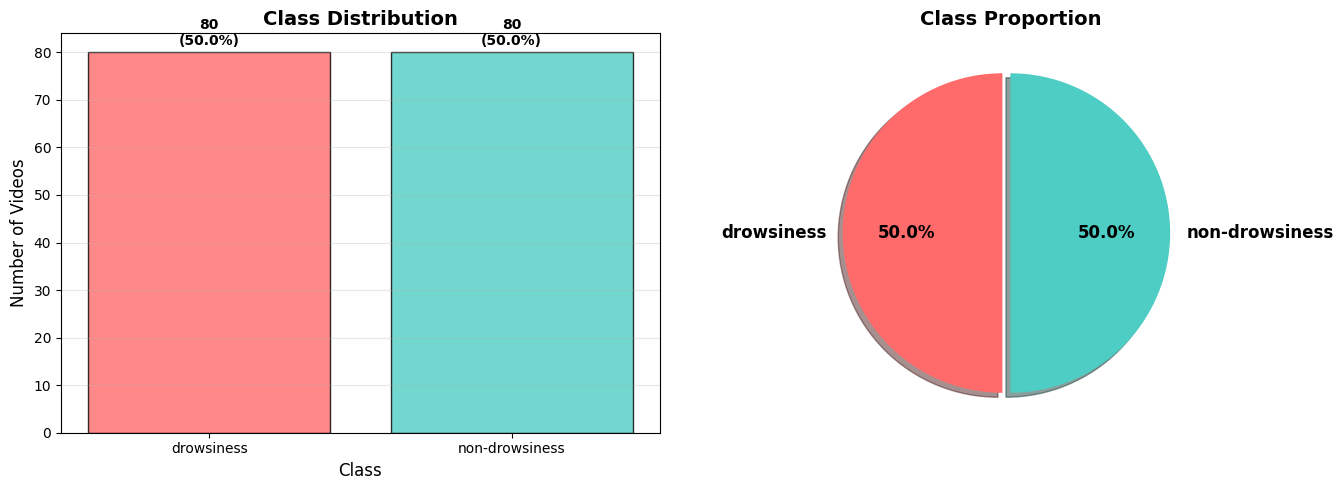

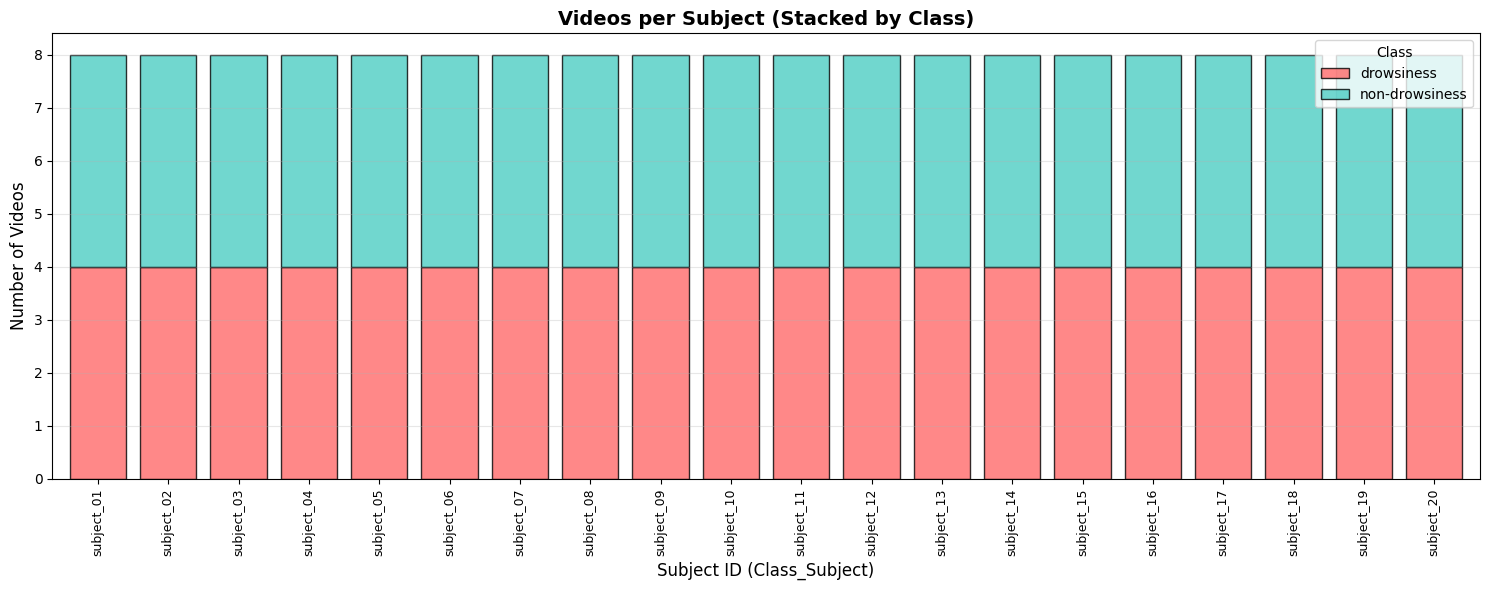


Class Distribution Summary:
class
drowsiness        80
non-drowsiness    80
Name: count, dtype: int64

Balance Ratio: 1.00
Data relatif seimbang.


In [8]:
if 'df' in locals() and not df.empty:
    
    # ANALISIS KESEIMBANGAN KELAS
    class_counts = df['class'].value_counts()
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar Plot
    colors = ['#FF6B6B', '#4ECDC4']
    axes[0].bar(class_counts.index, class_counts.values, color=colors, alpha=0.8, edgecolor='black')
    axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Number of Videos', fontsize=12)
    axes[0].set_xlabel('Class', fontsize=12)
    axes[0].grid(axis='y', alpha=0.3)

    # Tambahkan label angka di atas bar
    for i, count in enumerate(class_counts.values):
        axes[0].text(i, count + (max(class_counts.values)*0.02), 
                     f'{count:,}\n({count/len(df)*100:.1f}%)',
                     ha='center', fontsize=10, fontweight='bold')

    # Pie Chart
    axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
                colors=colors, startangle=90, explode=(0.05, 0), shadow=True,
                textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # DISTRIBUSI PER SUBJEK 
    subject_dist = df.groupby(['subject', 'class']).size().unstack(fill_value=0)
    
    # Urutkan agar tampilan rapi
    subject_dist = subject_dist.sort_index()

    fig, ax = plt.subplots(figsize=(15, 6))
    subject_dist.plot(kind='bar', stacked=True, ax=ax, color=['#FF6B6B', '#4ECDC4'],
                     alpha=0.8, edgecolor='black', width=0.8)
    
    ax.set_title('Videos per Subject (Stacked by Class)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Subject ID (Class_Subject)', fontsize=12)
    ax.set_ylabel('Number of Videos', fontsize=12)
    ax.legend(title='Class', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    
    # Putar label sumbu X agar terbaca (karena ada 40 subjek)
    plt.xticks(rotation=90, fontsize=9)
    plt.tight_layout()
    plt.show()

    print("\nClass Distribution Summary:")
    print(class_counts)
    print(f"\nBalance Ratio: {class_counts.min() / class_counts.max():.2f}")
    if (class_counts.min() / class_counts.max()) < 0.5:
        print("Peringatan: Data tidak seimbang (Imbalanced Dataset).")
    else:
        print("Data relatif seimbang.")

else:
    print("Variabel 'df' tidak ditemukan atau kosong. Jalankan sel load_dataset_df dulu!")

Mengambil 32 frame dari total 542 frame video...


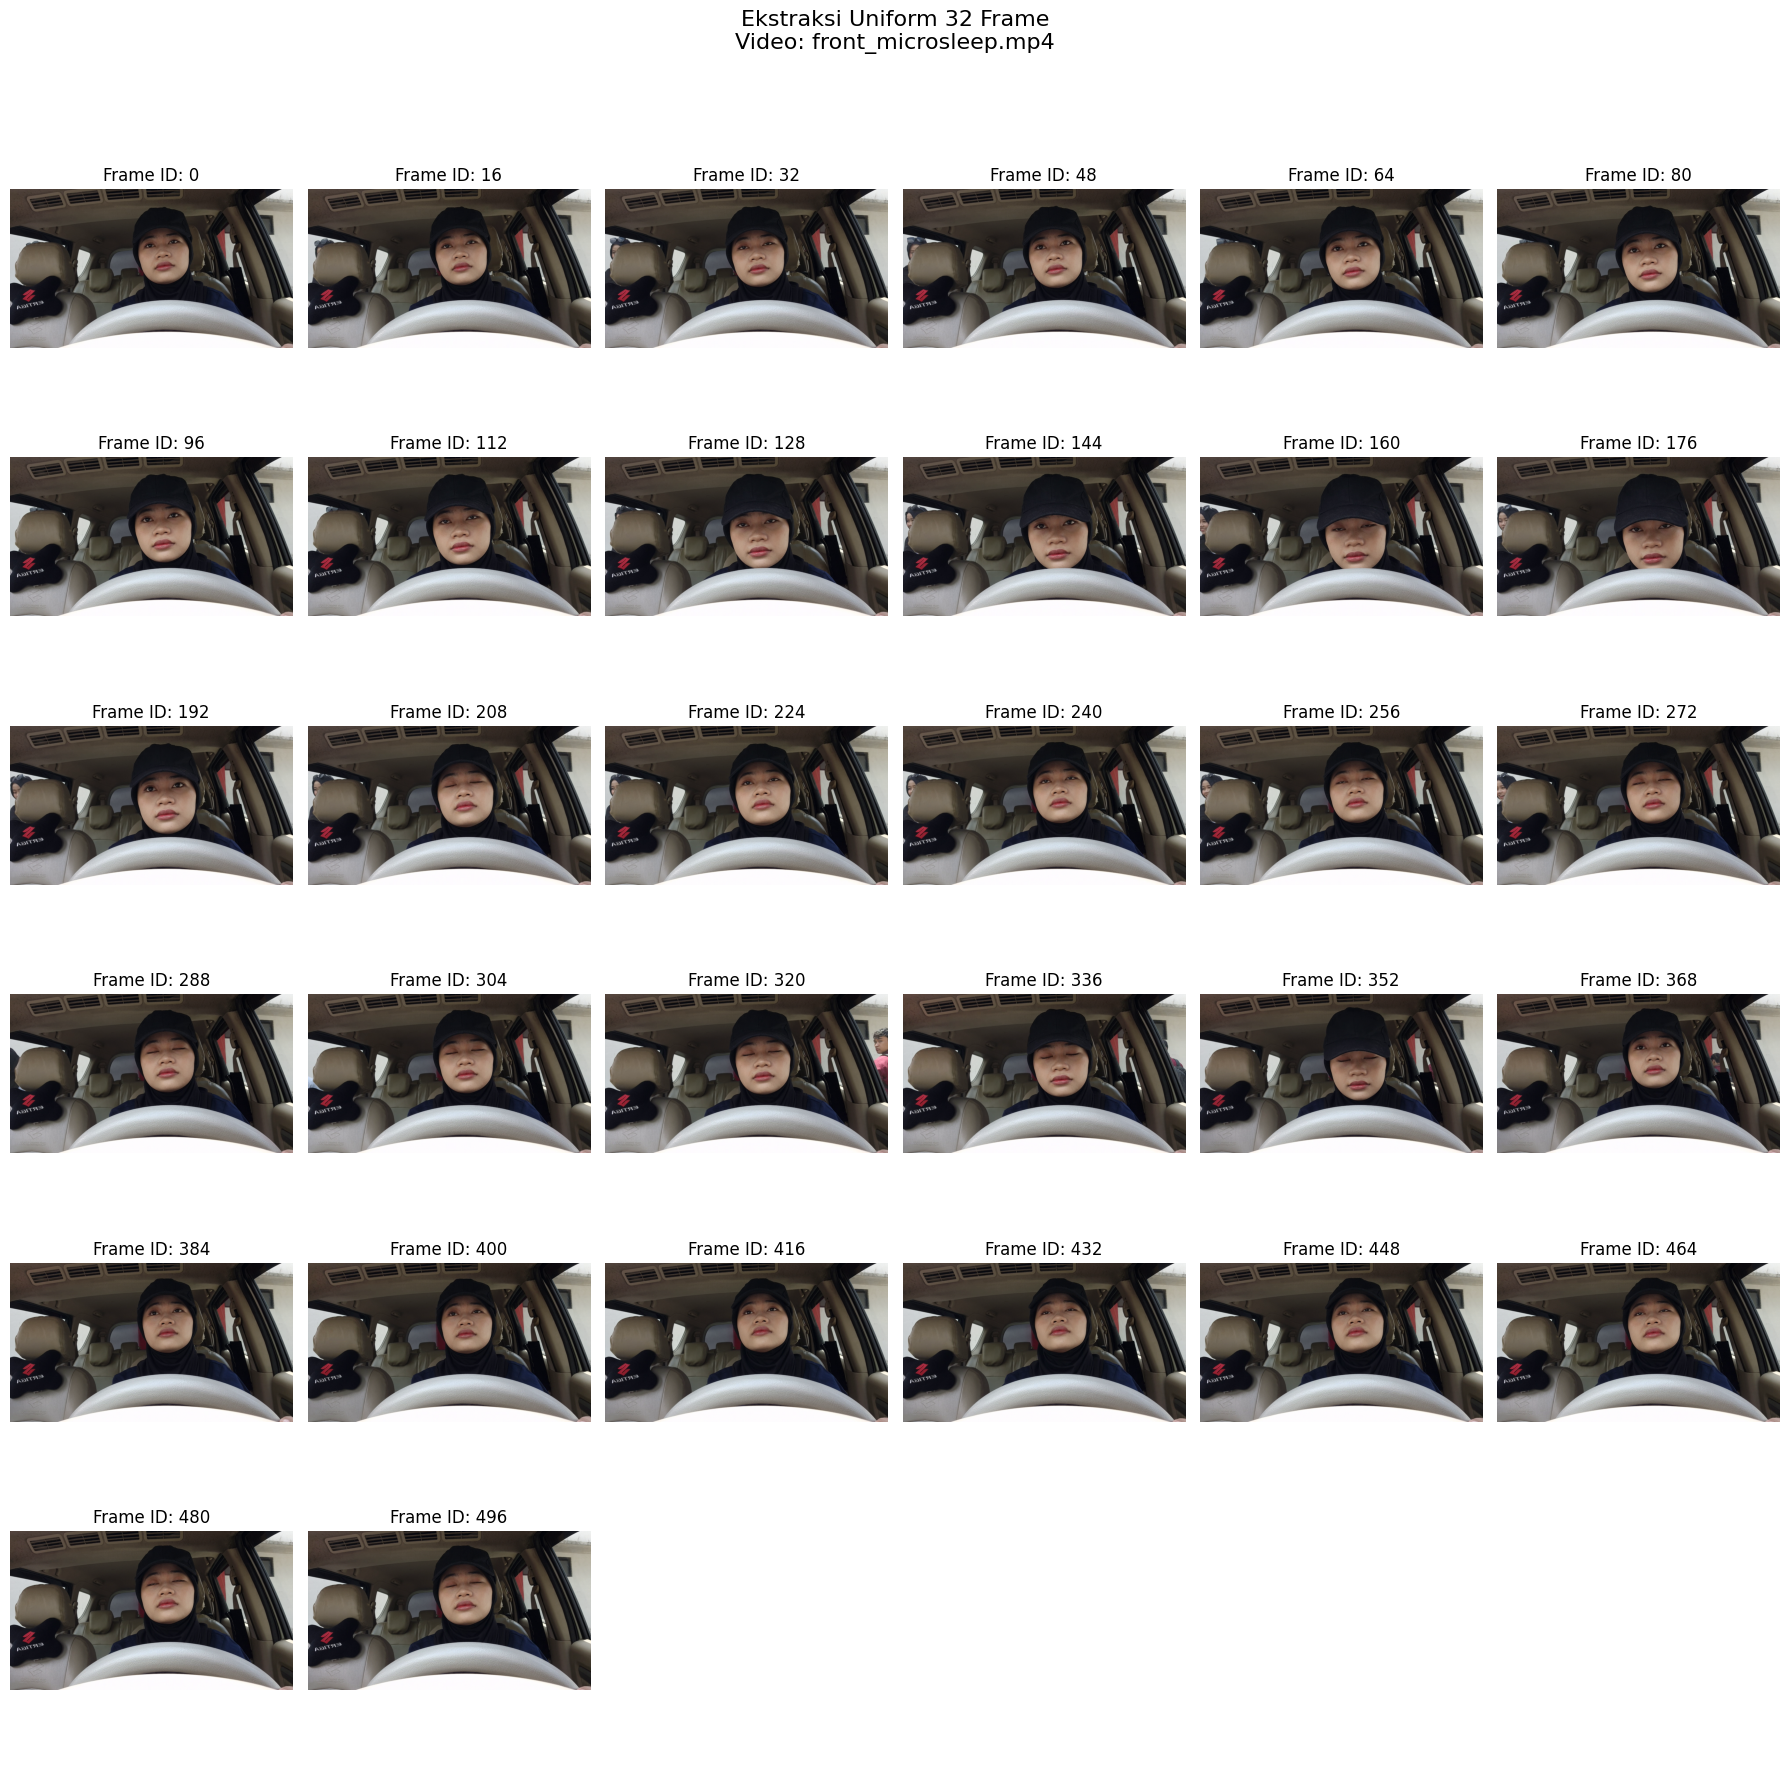

In [9]:
def extract_and_display_frames(video_path, num_frames=32, grid_cols=6):
    """
    Mengambil n frame secara merata dari video dan menampilkannya dalam grid.
    """
    
    if not os.path.exists(video_path):
        print(f"Error: File video tidak ditemukan di {video_path}")
        return

    cap = cv2.VideoCapture(video_path)
    # Mendapatkan total frame di video
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    if total_frames < num_frames:
        print(f"Peringatan: Video hanya punya {total_frames} frame, kurang dari {num_frames}.")
        
        # Jika frame kurang, kita ambil semua yang ada saja
        num_frames = total_frames

    # Menghitung interval agar frame diambil merata dari awal-akhir
    # Misal video 300 frame, mau ambil 30, berarti ambil frame 0, 10, 20...
    interval = total_frames // num_frames
    
    frames_list = []
    frame_indices = []

    print(f"Mengambil {num_frames} frame dari total {total_frames} frame video...")

    for i in range(num_frames):
        # Tentukan index frame yang mau diambil
        frame_id = i * interval
        
        # Pastikan tidak melewati total frame
        if frame_id >= total_frames:
            break
            
        # Set posisi opencv ke frame tersebut
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
        ret, frame = cap.read()
        
        if ret:

            # OpenCV baca dalam BGR, Matplotlib butuh RGB
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames_list.append(frame_rgb)
            frame_indices.append(frame_id)
        else:
            break

    cap.release()

    # Bagian Menampilkan Grid menggunakan Matplotlib
    # Hitung jumlah baris yang dibutuhkan
    num_captured = len(frames_list)
    grid_rows = (num_captured + grid_cols - 1) // grid_cols
    
    # Buat figure
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 3, grid_rows * 3))
    fig.suptitle(f'Ekstraksi Uniform {num_captured} Frame\nVideo: {os.path.basename(video_path)}', fontsize=16)
    
    # Flatten axes agar mudah di-iterasi (jika axes berupa array 2D)
    axes_flat = axes.flatten() if num_captured > 1 else [axes]

    for i, ax in enumerate(axes_flat):
        if i < num_captured:
            ax.imshow(frames_list[i])
            ax.set_title(f"Frame ID: {frame_indices[i]}")
            ax.axis('off') # Matikan sumbu x-y
        else:
            # Sembunyikan kotak grid yang kosong
            ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Atur jarak agar judul tidak tumpuk
    plt.show()

# CONTOH PENGGUNAAN 
# Pakai path dari CONFIG yang sudah kita perbaiki
path_video_tes = os.path.join(CONFIG.DATA_ROOT, 'drowsiness', 'subject_01', 'front_microsleep.mp4')

# Pastikan sel CONFIG sebelumnya sudah dijalankan
try:
    extract_and_display_frames(path_video_tes, num_frames=CONFIG.SEQ_LEN, grid_cols=6)
except NameError:
    print("Error: Variabel CONFIG belum didefinisikan. Jalankan sel konfigurasi path dulu.")
except Exception as e:
    print(f"Terjadi error: {e}")

In [10]:
# Tambahkan ini ke sel Config jika belum ada
# CONFIG.VISUAL_MODEL = "facebook/dinov2-large"

In [11]:
# Initialize DINOv2 Large & CLAHE Test

print("Loading DINOv2-Large Vision Transformer...")
print(f"   Model: {CONFIG.VISUAL_MODEL}")
print(f"   Device: {CONFIG.DEVICE}\n")

# Load model dan processor dari HuggingFace
processor = AutoImageProcessor.from_pretrained(CONFIG.VISUAL_MODEL)
visual_model = AutoModel.from_pretrained(CONFIG.VISUAL_MODEL).to(CONFIG.DEVICE)
visual_model.eval()

print("DINOv2 Model loaded successfully")
print(f"   Output Dimension: 1024 (Large version)")

Loading DINOv2-Large Vision Transformer...
   Model: facebook/dinov2-large
   Device: cpu



Loading weights: 100%|██████████| 439/439 [00:00<00:00, 2395.38it/s]

DINOv2 Model loaded successfully
   Output Dimension: 1024 (Large version)


Memproses Video Sample: c:\Users\User\SKRIPSI\drowsiness dataset\drowsiness\subject_06\front_microsleep.mp4


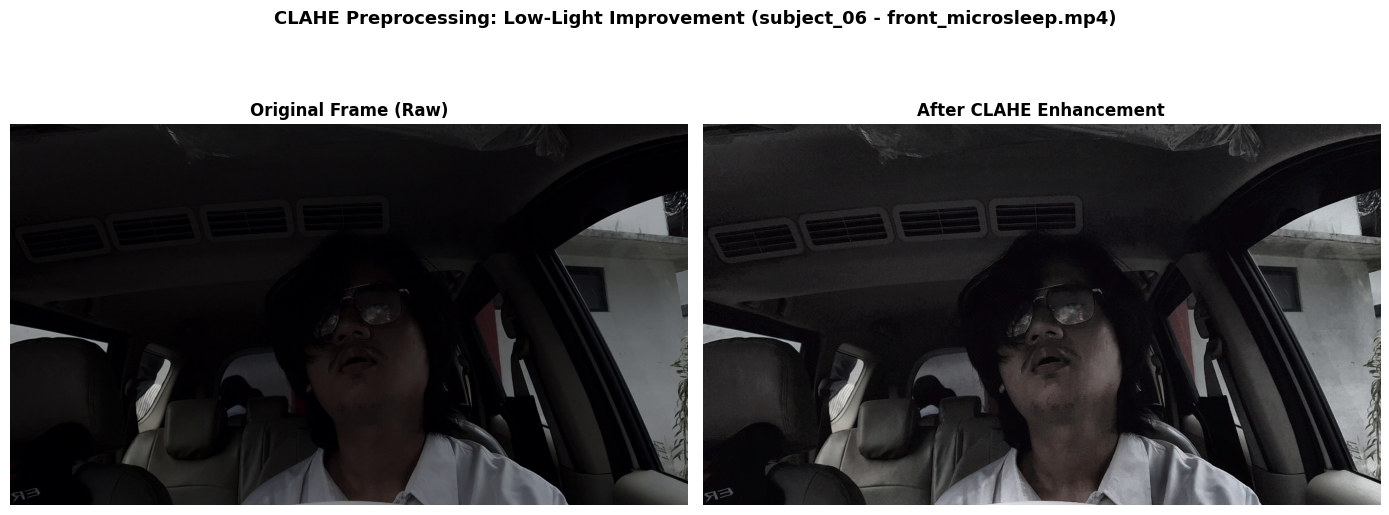

Statistik Intensitas Piksel:
   • Original Frame - Mean: 22.62, Std: 31.27
   • CLAHE Enhanced - Mean: 42.65, Std: 42.61


In [12]:
# CLAHE FUNCTION
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)

    enhanced = cv2.merge((cl, a, b))
    return cv2.cvtColor(enhanced, cv2.COLOR_LAB2RGB)

# PENGUJIAN CLAHE PADA SAMPEL FRAME
target_class   = 'drowsiness'
target_subject = 'subject_06'
target_video   = 'front_microsleep.mp4'

sample_query = df[
    (df['class'] == target_class) &
    (df['subject'] == target_subject) &
    (df['video'] == target_video)
]

if sample_query.empty:
    print(f"Video '{target_video}' untuk {target_subject} ({target_class}) tidak ditemukan di DataFrame.")
    # Fallback: ambil baris pertama yang tersedia
    sample_video = df.iloc[0]
    print(f"Menggunakan fallback sampel: {sample_video['subject']} - {sample_video['video']}")
else:
    sample_video = sample_query.iloc[0]

video_path = sample_video['path']
print(f"Memproses Video Sample: {video_path}")

cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)
ret, frame = cap.read()
cap.release()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame_clahe = apply_clahe(frame)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(frame_rgb)
    axes[0].set_title('Original Frame (Raw)', fontsize=12, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(frame_clahe)
    axes[1].set_title('After CLAHE Enhancement', fontsize=12, fontweight='bold')
    axes[1].axis('off')

    plt.suptitle(
        f"CLAHE Preprocessing: Low-Light Improvement ({sample_video['subject']} - {sample_video['video']})",
        fontsize=13,
        fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

    print(f"Statistik Intensitas Piksel:")
    print(f"   • Original Frame - Mean: {frame_rgb.mean():.2f}, Std: {frame_rgb.std():.2f}")
    print(f"   • CLAHE Enhanced - Mean: {frame_clahe.mean():.2f}, Std: {frame_clahe.std():.2f}")
else:
    print(f"Gagal membaca frame dari video di jalur: {video_path}")

In [13]:
# Tambahkan ke sel Config atau jalankan terpisah
CONFIG.FACE_DETECTION_CONFIDENCE = 0.5
CONFIG.FACE_MESH_CONFIDENCE = 0.5

In [14]:
import mediapipe as mp
print(mp.__version__)

0.10.14


In [15]:
# Akses solutions langsung dari mp
face_detection_model = mp.solutions.face_detection.FaceDetection(
    model_selection=1,
    min_detection_confidence=0.5
)

face_mesh_model = mp.solutions.face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

print("Berhasil!")

Berhasil!


In [16]:
# Initialize MediaPipe (Final Working Version)

print("Inisialisasi MediaPipe Face Analysis...")

try:
    # Menggunakan akses langsung via mp.solutions sesuai keberhasilanmu
    face_detection_model = mp.solutions.face_detection.FaceDetection(
        model_selection=1, # 1 untuk jarak jauh/dashboard, 0 untuk selfie
        min_detection_confidence=getattr(CONFIG, 'FACE_DETECTION_CONFIDENCE', 0.5)
    )

    face_mesh_model = mp.solutions.face_mesh.FaceMesh(
        static_image_mode=True, # Wajib True untuk ekstraksi per frame
        max_num_faces=1,
        refine_landmarks=True,
        min_detection_confidence=getattr(CONFIG, 'FACE_MESH_CONFIDENCE', 0.5)
    )
    
    print("MediaPipe initialized successfully!")
    
except Exception as e:
    print(f"Terjadi kesalahan saat inisialisasi: {e}")

print("MediaPipe initialized")
print(f"   → Face Detection Confidence: {CONFIG.FACE_DETECTION_CONFIDENCE}")
print(f"   → Face Mesh Landmarks: 468 points (with iris refinement)")

Inisialisasi MediaPipe Face Analysis...
MediaPipe initialized successfully!
MediaPipe initialized
   → Face Detection Confidence: 0.5
   → Face Mesh Landmarks: 468 points (with iris refinement)


In [17]:
# Indeks landmark (Tetap definisikan ini untuk hitung EAR/MAR nanti)
LEFT_EYE_IDX = [33, 160, 158, 133, 153, 144]
RIGHT_EYE_IDX = [362, 385, 387, 263, 373, 380]
LIPS_IDX = [78, 81, 13, 311, 308, 402, 14, 178]

# MAR (Mouth Aspect Ratio) - Titik bibir dalam & luar
LIPS_IDX = [78, 81, 13, 311, 308, 402, 14, 178]

# Model 3D untuk Head Pose (Sangat berguna untuk fitur tambahan 'distraction')
MODEL_POINTS_3D = np.array([
    (0.0, 0.0, 0.0),             # Nose tip
    (0.0, -330.0, -65.0),        # Chin
    (-225.0, 170.0, -135.0),     # Left eye left corner
    (225.0, 170.0, -135.0),      # Right eye right corner
    (-150.0, -150.0, -125.0),    # Left mouth corner
    (150.0, -150.0, -125.0)      # Right mouth corner
], dtype=np.float64)

print("Landmark indices defined")
print(f"   → EAR: {len(LEFT_EYE_IDX) + len(RIGHT_EYE_IDX)} points")
print(f"   → MAR: {len(LIPS_IDX)} points")
print(f"   Head Pose: {len(MODEL_POINTS_3D)} reference points")

Landmark indices defined
   → EAR: 12 points
   → MAR: 8 points
   Head Pose: 6 reference points


In [18]:
CONFIG.FACE_MARGIN = 0.2  # Margin 20%

Face Cropping Demonstration (Random Selection):



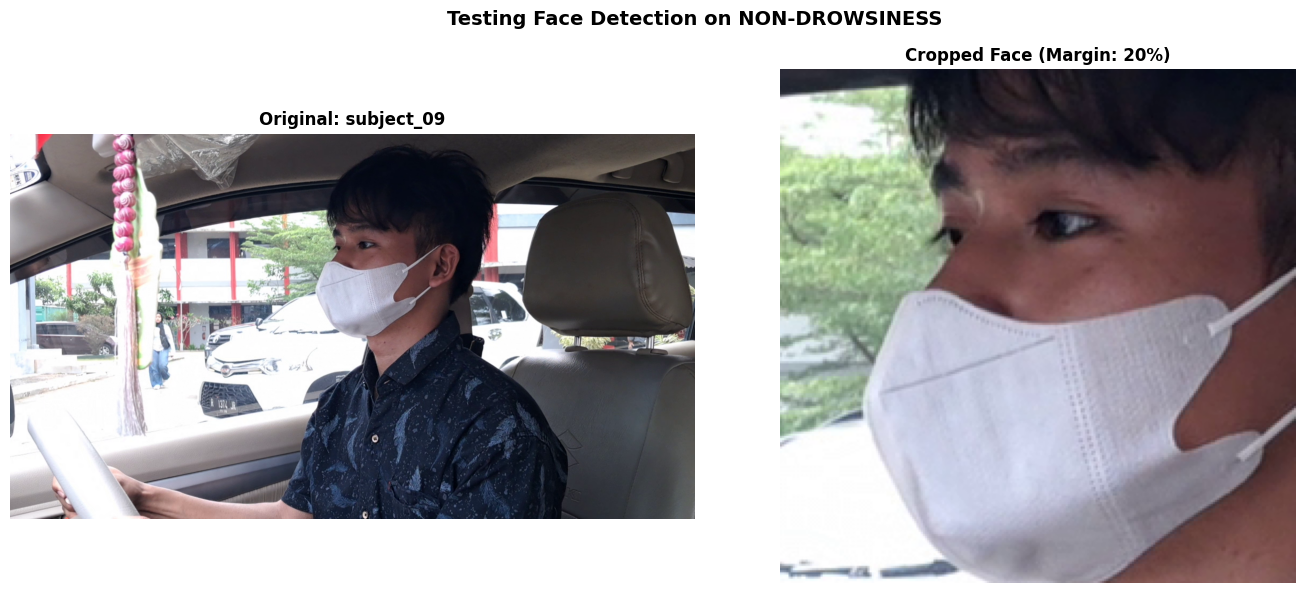

Berhasil memproses: subject_09
   • Path: c:\Users\User\SKRIPSI\drowsiness dataset\non-drowsiness\subject_09\side_talking.mp4
   • Reduction: 93.7%


In [19]:
# Face Cropping with Adaptive Margin (Random Test Mode)

def crop_face(img, detection):
    """
    Crop face region dengan margin adaptif agar fitur wajah tidak terpotong.
    """
    h, w = img.shape[:2]
    box = detection.location_data.relative_bounding_box

    # Convert relative coordinates to absolute pixels
    xmin = int(box.xmin * w)
    ymin = int(box.ymin * h)
    width = int(box.width * w)
    height = int(box.height * h)

    # Tambahkan margin
    margin_x = int(width * CONFIG.FACE_MARGIN)
    margin_y = int(height * CONFIG.FACE_MARGIN)

    # Calculate crop coordinates with boundary checks
    x1 = max(0, xmin - margin_x)
    y1 = max(0, ymin - margin_y)
    x2 = min(w, xmin + width + margin_x)
    y2 = min(h, ymin + height + margin_y)

    return img[y1:y2, x1:x2]

# Visualisasi Hasil Cropping
print("Face Cropping Demonstration (Random Selection):\n")

if not df.empty:

    # BAGIAN RANDOM_STATE DIHAPUS agar bisa tes berbagai subjek berbeda tiap kali dirun
    sample_video = df.sample(1).iloc[0] 
    cap = cv2.VideoCapture(sample_video['path'])

    # Ambil frame tengah
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ret, frame = cap.read()
    cap.release()

    if ret:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Gunakan face_detection_model yang sudah kita inisialisasi tadi
        det_res = face_detection_model.process(rgb)

        if det_res.detections:

            # Ambil deteksi dengan skor tertinggi
            best_det = max(det_res.detections, key=lambda d: d.score[0])
            cropped = crop_face(frame, best_det)
            cropped_rgb = cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)

            # Plotting
            fig, axes = plt.subplots(1, 2, figsize=(14, 6))

            axes[0].imshow(rgb)
            axes[0].set_title(f"Original: {sample_video['subject']}", fontsize=12, fontweight='bold')
            axes[0].axis('off')

            axes[1].imshow(cropped_rgb)
            axes[1].set_title(f'Cropped Face (Margin: {int(CONFIG.FACE_MARGIN*100)}%)',
                             fontsize=12, fontweight='bold')
            axes[1].axis('off')

            plt.suptitle(f"Testing Face Detection on {sample_video['class'].upper()}",
                         fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()

            print(f"Berhasil memproses: {sample_video['subject']}")
            print(f"   • Path: {sample_video['path']}")
            print(f"   • Reduction: {(1 - cropped.size/frame.size)*100:.1f}%")
        else:
            print(f"Wajah tidak terdeteksi pada {sample_video['subject']}. Coba jalankan lagi.")
    else:
        print(f"Gagal membaca video: {sample_video['path']}")
else:
    print("DataFrame kosong.")

In [20]:
# EAR & MAR Computation Functions

def calculate_ear(landmarks_pixel, eye_indices):
    """
    Calculate Eye Aspect Ratio (EAR)

    Formula:
        EAR = (||p2-p6|| + ||p3-p5||) / (2 * ||p1-p4||)

    Where:
        p1, p4 = Horizontal eye corners
        p2, p3, p5, p6 = Vertical eye points

    Clinical Interpretation:
        - EAR ≈ 0.3: Mata terbuka normal
        - EAR < 0.25: Mata tertutup (blink/microsleep)
        - EAR < 0.2: Mata tertutup penuh (sustained closure)

    Reference:
        Soukupová & Čech (2016) - "Real-Time Eye Blink Detection using Facial Landmarks"
    """
    # Mengambil koordinat (x, y) dalam pixel untuk mata
    points = landmarks_pixel[eye_indices]

    # Vertical distances (jarak vertikal antara kelopak mata)
    A = np.linalg.norm(points[1] - points[5])
    B = np.linalg.norm(points[2] - points[4])

    # Horizontal distance (jarak horizontal antara sudut mata)
    C = np.linalg.norm(points[0] - points[3])

    # EAR calculation with epsilon to prevent division by zero
    ear = (A + B) / (2.0 * C + 1e-6)

    return ear

def calculate_mar(landmarks_pixel, mouth_indices):
    """
    Calculate Mouth Aspect Ratio (MAR)

    Formula:
        MAR = (||p2-8|| + ||p3-p7|| + ||p4-p6||) / (3 * ||p1-p5||)

    Where:
        p1, p5 = Horizontal mouth corners
        p2, p3, p4, p6, p7, p8 = Vertical mouth points

    Clinical Interpretation:
        - MAR < 0.5: Mulut tertutup (normal/talking ringan)
        - MAR 0.5-0.6: Talking aktif
        - MAR > 0.6: Yawning (menguap)
        - MAR > 0.8: Yawning ekstrem

    Key Differentiator:
        Kombinasi dengan EAR memisahkan Yawning (EAR↓ + MAR↑)
        dari Talking (EAR≈0.3 + MAR↑)
    """
    # Mengambil koordinat (x, y) dalam pixel untuk mulut
    points = landmarks_pixel[mouth_indices]

    # Vertical distances (3 measurements for robustness)
    A = np.linalg.norm(points[1] - points[7])
    B = np.linalg.norm(points[2] - points[6])
    C = np.linalg.norm(points[3] - points[5])

    # Horizontal distance
    D = np.linalg.norm(points[0] - points[4])

    # MAR calculation
    mar = (A + B + C) / (3.0 * D + 1e-6)

    return mar

print("EAR & MAR functions defined")
print("\nClinical Thresholds:")
print("   EAR (Eyes):")
print("      • Normal : 0.25 - 0.35")
print("      • Drowsy : < 0.25")
print("      • Closed : < 0.20")
print("\n   MAR (Mouth):")
print("      • Closed : < 0.50")
print("      • Talking: 0.50 - 0.60")
print("      • Yawning: > 0.60")

EAR & MAR functions defined

Clinical Thresholds:
   EAR (Eyes):
      • Normal : 0.25 - 0.35
      • Drowsy : < 0.25
      • Closed : < 0.20

   MAR (Mouth):
      • Closed : < 0.50
      • Talking: 0.50 - 0.60
      • Yawning: > 0.60


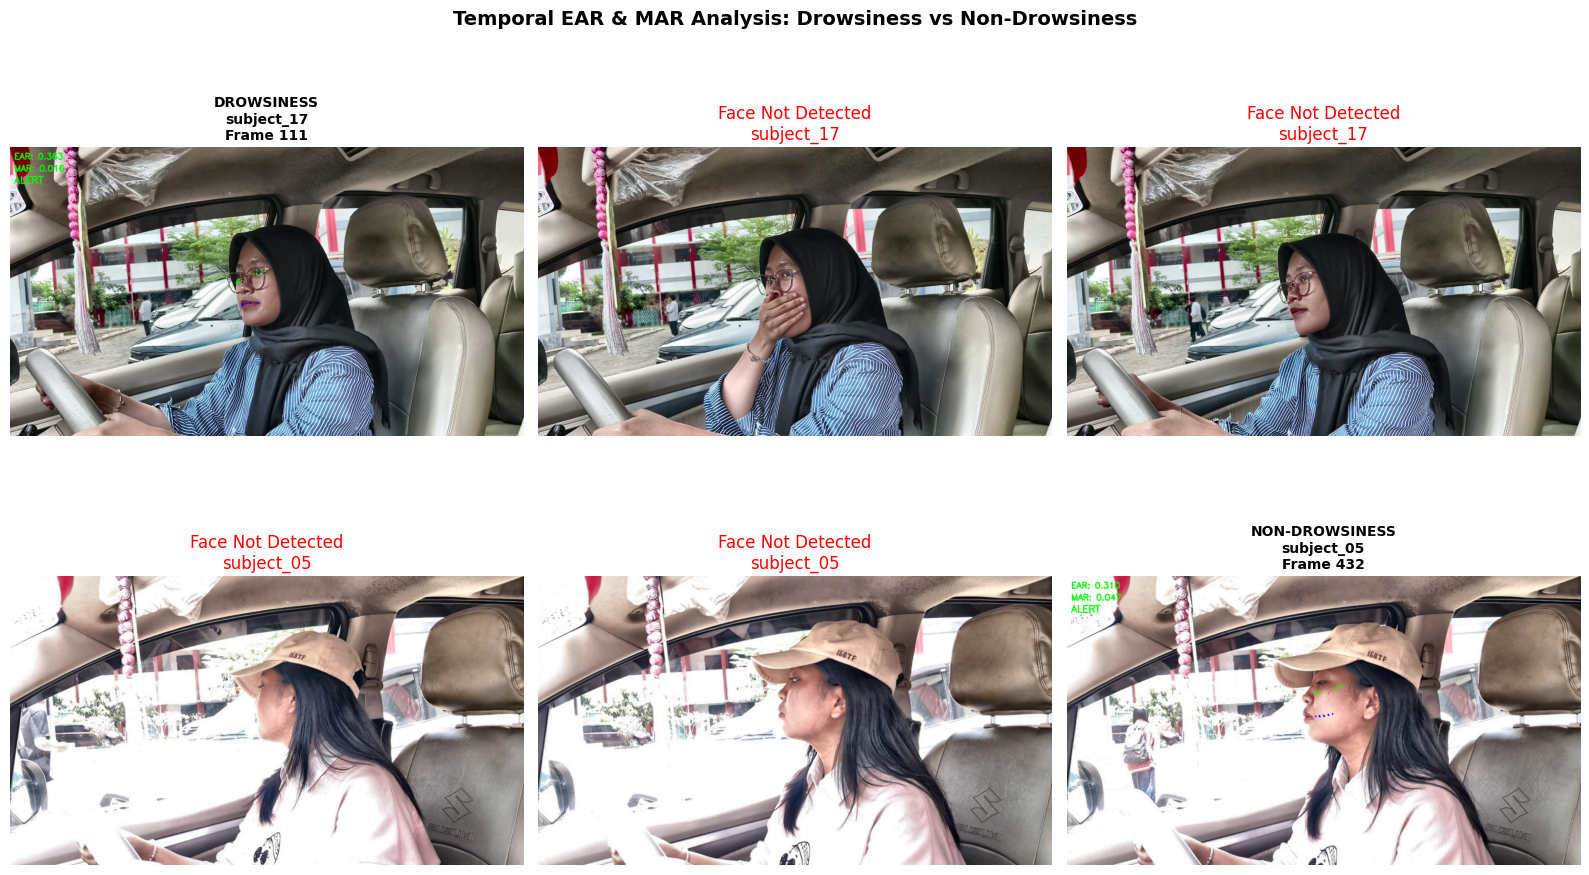

Visualization complete for subjects chosen at random


In [21]:
# Visualize EAR & MAR on Random Sample Frames

def draw_landmarks_with_ratios(img, landmarks, ear_left, ear_right, mar):
    """
    Visualize landmarks dengan overlay EAR & MAR values dalam format RGB
    """
    h, w = img.shape[:2]
    overlay = img.copy()

    # Convert normalized landmarks to pixel coordinates
    lm_pixels = [(int(p.x * w), int(p.y * h)) for p in landmarks]

    # Draw eye landmarks (green)
    for idx in LEFT_EYE_IDX + RIGHT_EYE_IDX:
        cv2.circle(overlay, lm_pixels[idx], 2, (0, 255, 0), -1)

    # Draw mouth landmarks (blue dalam format RGB)
    for idx in LIPS_IDX:
        cv2.circle(overlay, lm_pixels[idx], 2, (0, 0, 255), -1)

    # Hitung rata-rata EAR
    avg_ear = (ear_left + ear_right) / 2

    # Color coding berdasarkan threshold
    ear_color = (0, 255, 0) if avg_ear > 0.25 else (255, 0, 0) # Hijau jika normal, Merah jika ngantuk
    mar_color = (0, 255, 0) if mar < 0.6 else (255, 165, 0)   # Hijau jika normal, Oranye jika menguap

    # Overlay text ke gambar
    cv2.putText(overlay, f'EAR: {avg_ear:.3f}', (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, ear_color, 2)
    cv2.putText(overlay, f'MAR: {mar:.3f}', (10, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, mar_color, 2)

    # Interpretasi Status
    if avg_ear < 0.25 and mar > 0.6:
        status, color = "YAWNING", (255, 165, 0)
    elif avg_ear < 0.25:
        status, color = "DROWSY", (255, 0, 0)
    elif mar > 0.6:
        status, color = "TALKING/YAWN", (255, 255, 0)
    else:
        status, color = "ALERT", (0, 255, 0)

    cv2.putText(overlay, status, (10, 90),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

    return overlay

# Main Visualization Loop
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Iterasi untuk tiap kelas
for class_idx, class_name in enumerate(['drowsiness', 'non-drowsiness']):
    samples_in_class = df[df['class'] == class_name]

    if not samples_in_class.empty:

        # RANDOM_STATE DIHAPUS: Agar subjek berganti tiap kali sel dijalankan
        sample = samples_in_class.sample(1).iloc[0]
        
        cap = cv2.VideoCapture(sample['path'])
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        # Ambil 3 frame: Awal (25%), Tengah (50%), Akhir (75%)
        frame_indices = [total//4, total//2, 3*total//4]

        for i, frame_idx in enumerate(frame_indices):
            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
            ret, frame = cap.read()

            if ret:
                # 1. Preprocessing: CLAHE (Memperjelas gambar gelap)
                # apply_clahe mengembalikan RGB
                img_enhanced_rgb = apply_clahe(frame)
                h_img, w_img = img_enhanced_rgb.shape[:2]

                # 2. MediaPipe Face Mesh Process
                result = face_mesh_model.process(img_enhanced_rgb)

                if result.multi_face_landmarks:
                    landmarks = result.multi_face_landmarks[0].landmark
                    
                    # Konversi landmarks ke format numpy pixel untuk fungsi hitung
                    lm_pixel = np.array([(p.x * w_img, p.y * h_img) for p in landmarks])

                    # 3. Hitung Rasio menggunakan fungsi calculate_ear & calculate_mar
                    ear_l = calculate_ear(lm_pixel, LEFT_EYE_IDX)
                    ear_r = calculate_ear(lm_pixel, RIGHT_EYE_IDX)
                    mar_val = calculate_mar(lm_pixel, LIPS_IDX)

                    # 4. Gambar Landmark dan Overlay ke Image
                    vis = draw_landmarks_with_ratios(img_enhanced_rgb, landmarks, ear_l, ear_r, mar_val)

                    axes[class_idx, i].imshow(vis)
                    axes[class_idx, i].set_title(f"{class_name.upper()}\n{sample['subject']}\nFrame {frame_idx}",
                                                 fontsize=10, fontweight='bold')
                else:
                    axes[class_idx, i].imshow(img_enhanced_rgb)
                    axes[class_idx, i].set_title(f"Face Not Detected\n{sample['subject']}", color='red')
                
                axes[class_idx, i].axis('off')
            else:
                axes[class_idx, i].text(0.5, 0.5, "Error Load Frame", ha='center')
                axes[class_idx, i].axis('off')
        
        cap.release()

plt.suptitle('Temporal EAR & MAR Analysis: Drowsiness vs Non-Drowsiness',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Visualization complete for subjects chosen at random")

In [22]:
# Full Head Pose Estimation with Gimbal Lock Protection

def estimate_head_pose(landmarks, img_width, img_height):
    """
    Estimate Head Pose (Pitch, Yaw, Roll) menggunakan Perspective-n-Point (PnP)

    Clinical Significance:
        - Pitch < -20°: Head nodding (strong drowsiness indicator)
        - Yaw > |30°|: Looking away from road
        - Roll > |15°|: Head tilting (potential microsleep)

    Reference:
        - Murphy-Chutorian & Trivedi (2009): "Head Pose Estimation in Computer Vision"
    """
    # 6 Key Landmark Points (Urutan sesuai dengan MODEL_POINTS_3D)
    # 1: Nose, 152: Chin, 33: L Eye, 263: R Eye, 61: L Mouth, 291: R Mouth
    key_indices = [1, 152, 33, 263, 61, 291]

    # Map landmarks ke koordinat pixel
    img_points = np.array([
        [landmarks[idx].x * img_width, landmarks[idx].y * img_height]
        for idx in key_indices
    ], dtype=np.float64)

    # Setup Camera Matrix (Pinhole Model)
    focal_length = img_width
    center = (img_width / 2, img_height / 2)
    camera_matrix = np.array([
        [focal_length, 0, center[0]],
        [0, focal_length, center[1]],
        [0, 0, 1]
    ], dtype=np.float64)

    # Distortion Coefficients (Asumsi lensa flat/no distortion)
    dist_coeffs = np.zeros((4, 1))

    try:
        # Solve PnP
        success, rotation_vec, translation_vec = cv2.solvePnP(
            MODEL_POINTS_3D, 
            img_points, 
            camera_matrix, 
            dist_coeffs, 
            flags=cv2.SOLVEPNP_ITERATIVE
        )

        if not success:
            return 0.0, 0.0, 0.0

        # Get Rotation Matrix
        rotation_mat, _ = cv2.Rodrigues(rotation_vec)

        # Decompose ke Euler Angles
        pose_mat = cv2.hconcat([rotation_mat, translation_vec])
        _, _, _, _, _, _, euler_angles = cv2.decomposeProjectionMatrix(pose_mat)

        # Ambil sudut mentah (dalam derajat)
        pitch = euler_angles[0, 0] # X (Nunduk/Dongak)
        yaw = euler_angles[1, 0]   # Y (Toleh Kiri/Kanan)
        roll = euler_angles[2, 0]  # Z (Miring Kiri/Kanan)

        # PERLINDUNGAN GIMBAL LOCK & DISKONTINUITAS
        # Memastikan sudut tetap di rentang [-180, 180] agar tidak ada lompatan drastis
        def wrap_angle(angle):
            while angle > 180: angle -= 360
            while angle < -180: angle += 360
            return angle

        pitch = wrap_angle(pitch)
        yaw = wrap_angle(yaw)
        roll = wrap_angle(roll)

        # NORMALISASI UNTUK MODEL AI (-1.0 sampai 1.0)
        # Kita gunakan pembagi 90.0 karena rotasi kepala manusia jarang melebihi 90 derajat
        # Pitch dikali -1 agar Nunduk bernilai NEGATIF (Drowsiness Indicator)
        pitch_norm = np.clip(-pitch / 90.0, -1.0, 1.0)
        yaw_norm   = np.clip(yaw / 90.0, -1.0, 1.0)
        roll_norm  = np.clip(roll / 90.0, -1.0, 1.0)

        return float(pitch_norm), float(yaw_norm), float(roll_norm)

    except Exception as e:
        # Fallback jika terjadi error matematika (division by zero, dll)
        return 0.0, 0.0, 0.0

print("Head Pose Estimation function defined")

# BAGIAN INTERPRETASI
print("\nAngle Interpretations (Normalized Range -1 to 1):")
print("   Pitch (Nodding):")
print("      • Positive: Looking up")
print("      • Negative: Looking down (drowsiness indicator)")
print("      • Threshold: < -0.3 = Strong drowsiness")
print("\n   Yaw (Turning):")
print("      • Positive: Looking right")
print("      • Negative: Looking left")
print("      • Threshold: > |0.4| = Distracted")
print("\n   Roll (Tilting):")
print("      • Positive: Tilting right")
print("      • Negative: Tilting left")
print("      • Threshold: > |0.2| = Potential microsleep")

Head Pose Estimation function defined

Angle Interpretations (Normalized Range -1 to 1):
   Pitch (Nodding):
      • Positive: Looking up
      • Negative: Looking down (drowsiness indicator)
      • Threshold: < -0.3 = Strong drowsiness

   Yaw (Turning):
      • Positive: Looking right
      • Negative: Looking left
      • Threshold: > |0.4| = Distracted

   Roll (Tilting):
      • Positive: Tilting right
      • Negative: Tilting left
      • Threshold: > |0.2| = Potential microsleep


In [23]:
def extract_geometric_features(frame_rgb):
    """
    Helper untuk menyatukan EAR, MAR, dan Pose dalam satu array (5 dim).
    """
    h, w = frame_rgb.shape[:2]
    result = face_mesh_model.process(frame_rgb)

    if result.multi_face_landmarks:
        landmarks = result.multi_face_landmarks[0].landmark
        lm_pixel = np.array([(p.x * w, p.y * h) for p in landmarks])

        # EAR & MAR
        ear_l = calculate_ear(lm_pixel, LEFT_EYE_IDX)
        ear_r = calculate_ear(lm_pixel, RIGHT_EYE_IDX)
        ear_avg = (ear_l + ear_r) / 2.0
        mar = calculate_mar(lm_pixel, LIPS_IDX)

        # Head Pose (Pitch, Yaw, Roll)
        pitch, yaw, roll = estimate_head_pose(landmarks, w, h)

        return np.array([ear_avg, mar, pitch, yaw, roll], dtype=np.float32)

    return np.zeros(5, dtype=np.float32)

In [24]:
# Main Video Processing Pipeline

def process_video_to_features(video_path, save_path, is_image_sequence=False):
    # Skip jika sudah diproses (efisiensi jika restart runtime)
    if os.path.exists(save_path):
        return

    frames_to_process = []

    # LOAD & SAMPLE FRAMES
    if not is_image_sequence:
        cap = cv2.VideoCapture(video_path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total_frames > 0:
            sample_indices = np.linspace(0, total_frames - 1, CONFIG.SEQ_LEN, dtype=int)

            # Langsung lompat ke frame yang diinginkan
            for idx in sample_indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret and frame is not None:
                    frames_to_process.append(frame)
        cap.release()
    else:
        # Untuk data test yang berbentuk folder JPG
        image_files = sorted(glob.glob(os.path.join(video_path, "*.jpg")))
        if len(image_files) > 0:
            sample_indices = np.linspace(0, len(image_files) - 1, CONFIG.SEQ_LEN, dtype=int)
            for idx in sample_indices:
                frame = cv2.imread(image_files[idx])
                if frame is not None:
                    frames_to_process.append(frame)

    # Safety: Handle jika video kosong
    if len(frames_to_process) == 0:
        np.save(save_path, np.zeros((CONFIG.SEQ_LEN, CONFIG.INPUT_DIM), dtype=np.float32))
        return

    # PREPROCESSING & GEOMETRIC EXTRACTION
    processed_faces = []
    geometric_features = []
    last_valid_geo = np.array([0.30, 0.10, 0.0, 0.0, 0.0], dtype=np.float32)  # Default: EAR=0.3

    for frame in frames_to_process:
        # CLAHE langsung mengembalikan format RGB (tanpa cvtColor ganda)
        rgb = apply_clahe(frame)

        # Face Detection menggunakan model yang sudah dibuat
        detection_result = face_detection_model.process(rgb)

        if detection_result.detections:
            best_detection = max(detection_result.detections, key=lambda d: d.score[0])
            face_crop = crop_face(rgb, best_detection)
        else:
            face_crop = rgb

        # Geometric Extraction (EAR, MAR, Pose)
        geo_feat = extract_geometric_features(rgb)

        # Forward fill jika MediaPipe gagal deteksi wajah di frame ini
        if np.any(geo_feat != 0):
            last_valid_geo = geo_feat
        else:
            geo_feat = last_valid_geo

        # Resize wajah untuk DINOv2 (224x224)
        face_final = cv2.resize(face_crop, (224, 224))
        processed_faces.append(face_final)
        geometric_features.append(geo_feat)

    # PADDING (Jika frame kurang dari 32)
    while len(processed_faces) < CONFIG.SEQ_LEN:
        processed_faces.append(processed_faces[-1] if processed_faces else np.zeros((224, 224, 3), dtype=np.uint8))
        geometric_features.append(geometric_features[-1] if geometric_features else last_valid_geo)

    # DINOv2 BATCH INFERENCE
    visual_embeddings = []
    batch_size = 16 if CONFIG.DEVICE == "cuda" else 8

    for i in range(0, len(processed_faces), batch_size):
        batch_faces = processed_faces[i : i + batch_size]
        inputs = processor(images=batch_faces, return_tensors="pt").to(CONFIG.DEVICE)

        with torch.no_grad():
            outputs = visual_model(**inputs)
            batch_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            visual_embeddings.append(batch_embeddings)

    visual_features = np.concatenate(visual_embeddings, axis=0)[:CONFIG.SEQ_LEN]
    geometric_features = np.array(geometric_features[:CONFIG.SEQ_LEN], dtype=np.float32)

    # CONCATENATE & SAVE
    final_features = np.concatenate([visual_features, geometric_features], axis=1)
    np.save(save_path, final_features.astype(np.float32))

# Jalankan sel ini untuk mengunci definisi pipeline
print("Complete pipeline function defined & CPU-Optimized")
print("-" * 30)
print("Output Specification:")
print(f"   • Shape: ({CONFIG.SEQ_LEN}, 1029)")
print(f"   • Temporal: {CONFIG.SEQ_LEN} frames (Uniform Sampling)")
print("   • Feature Mapping per Frame:")
print("       [0000:1024] -> Visual Features (DINOv2 CLS Token)")
print("       [1024:1025] -> EAR (Eye Aspect Ratio)")
print("       [1025:1026] -> MAR (Mouth Aspect Ratio)")
print("       [1026:1027] -> Pitch (Head Nodding)")
print("       [1027:1028] -> Yaw (Head Turning)")
print("       [1028:1029] -> Roll (Head Tilting)")

Complete pipeline function defined & CPU-Optimized
------------------------------
Output Specification:
   • Shape: (32, 1029)
   • Temporal: 32 frames (Uniform Sampling)
   • Feature Mapping per Frame:
       [0000:1024] -> Visual Features (DINOv2 CLS Token)
       [1024:1025] -> EAR (Eye Aspect Ratio)
       [1025:1026] -> MAR (Mouth Aspect Ratio)
       [1026:1027] -> Pitch (Head Nodding)
       [1027:1028] -> Yaw (Head Turning)
       [1028:1029] -> Roll (Head Tilting)


In [25]:
# Check for Pre-extracted Features

TARGET_DIR = CONFIG.FEATURE_DIR

# Buat folder jika belum ada
os.makedirs(TARGET_DIR, exist_ok=True)

# Cek isi folder
all_files = os.listdir(TARGET_DIR)
existing_npy = [f for f in all_files if f.lower().endswith('.npy')]
total_npy = len(existing_npy)

if total_npy > 0:
    FEATURES_EXIST = True
    print("Fitur hasil extract ditemukan:")
    print(f"   • Path                 : {TARGET_DIR}")
    print(f"   • Total file .npy      : {total_npy} file")
    
    if total_npy >= len(df) and len(df) > 0:
        SKIP_EXTRACTION = True
        print("\nSemua video sudah berhasil diekstrak. Siap ke tahap Training.")
    else:
        SKIP_EXTRACTION = False
        print(f"\nBaru {total_npy}/{len(df)} video yang diekstrak. Sistem akan memproses sisanya.")
else:
    FEATURES_EXIST = False
    SKIP_EXTRACTION = False
    print(f"Belum ada hasil extract (.npy) di: {TARGET_DIR}")
    print("Persiapan menjalankan ekstraksi fitur...")

Fitur hasil extract ditemukan:
   • Path                 : c:\Users\User\SKRIPSI\drowsiness dataset\hasil-extract-2
   • Total file .npy      : 160 file

Semua video sudah berhasil diekstrak. Siap ke tahap Training.


In [26]:
# Execute Full Feature Extraction (Local Version)

# Sinkronisasi status folder terbaru
if not os.path.exists(CONFIG.FEATURE_DIR):
    os.makedirs(CONFIG.FEATURE_DIR, exist_ok=True)

# Hitung jumlah file yang sudah ada di laptop
existing_files = [f for f in os.listdir(CONFIG.FEATURE_DIR) if f.endswith('.npy')]
total_existing = len(existing_files)

# Jika jumlah file sudah sama dengan jumlah video di DataFrame, kita skip total
if total_existing >= len(df):
    print(f" Skipping extraction. (Semua {total_existing} fitur sudah lengkap di folder lokal!)")
    print(f" Lokasi: {CONFIG.FEATURE_DIR}")
else:
    print(" STARTING FEATURE EXTRACTION (LOCAL MODE)")
    print("="*70)
    print(f" Output Folder : {CONFIG.FEATURE_DIR}")

    # Siapkan daftar antrian (Jobs)
    extraction_jobs = []
    
    for _, row in df.iterrows():
        # Buat nama file unik: subject_01_front_microsleep.npy
        # Kita gunakan subject dan video name agar tidak tertukar
        video_name_clean = os.path.basename(row['path']).replace('.mp4', '').replace('.MP4', '')
        output_filename = f"{row['subject']}_{video_name_clean}.npy"
        output_path = os.path.join(CONFIG.FEATURE_DIR, output_filename)

        # Cek apakah file spesifik ini sudah ada? (Resume capability per file)
        if not os.path.exists(output_path):
            extraction_jobs.append((row['path'], output_path, False))

    if len(extraction_jobs) == 0:
        print("Semua file individu sudah ada. Tidak ada yang perlu diproses.")
    else:
        print(f"Total video baru yang akan diproses : {len(extraction_jobs)}")

        # Estimasi: 1 video = 1.5 menit (DINOv2 Large di CPU agak berat)
        print(f"  Estimasi waktu sisa                 : ~{len(extraction_jobs) * 1.5:.1f} menit")
        print("="*70)

        # Jalankan Ekstraksi dengan Progress Bar
        # Loop ini akan memanggil fungsi process_video_to_features yang sudah kita buat tadi
        for video_path, save_path, is_seq in tqdm(extraction_jobs, desc=" Extracting"):
            try:
                process_video_to_features(video_path, save_path, is_seq)
            except Exception as e:
                # Jika error, kita print tapi lanjut ke video berikutnya agar tidak berhenti total
                print(f"\nError pada {os.path.basename(video_path)}: {e}")
                continue

        print("\n" + "="*70)
        print("Feature extraction complete!")
        print(f"Cek hasil (.npy) di: {CONFIG.FEATURE_DIR}")

 Skipping extraction. (Semua 160 fitur sudah lengkap di folder lokal!)
 Lokasi: c:\Users\User\SKRIPSI\drowsiness dataset\hasil-extract-2


In [27]:
class DrowsinessFeatureDataset(Dataset):
    def __init__(self, file_paths, labels, augment: bool = False):
        self.file_paths = list(file_paths)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
        self.augment = augment

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx: int):
        # Load matrix .npy berukuran (32, 1029)
        features = np.load(self.file_paths[idx])
        features_tensor = torch.from_numpy(features).float()

        # Gaussian noise injection (hanya saat training)
        if self.augment:
            noise = torch.randn_like(features_tensor) * 0.01
            features_tensor = features_tensor + noise

        return features_tensor, self.labels[idx]

print("Dataset class defined")
print("\nData Flow:")
print("   • Input        : .npy file (32, 1029)")
print("   • Augmentation : Gaussian noise σ=0.01 (train only)")
print("   • Output       : Tensor (32, 1029) + LongTensor Label")

Dataset class defined

Data Flow:
   • Input        : .npy file (32, 1029)
   • Augmentation : Gaussian noise σ=0.01 (train only)
   • Output       : Tensor (32, 1029) + LongTensor Label


In [28]:
# Menghubungkan DataFrame video langsung dengan file .npy
df_features = df.copy()

# Format file di disk: {class}_{subject}_{video_name}.npy
df_features['feature_filename'] = df_features.apply(
    lambda row: f"{row['class']}_{row['subject']}_{os.path.splitext(row['video'])[0]}.npy", 
    axis=1
)

df_features['feature_path'] = df_features['feature_filename'].apply(
    lambda fname: os.path.join(CONFIG.FEATURE_DIR, fname)
)

# Filter hanya yang file fiturnya benar-benar ada di disk
df_features = df_features[df_features['feature_path'].apply(os.path.exists)].reset_index(drop=True)

if len(df_features) == 0:
    raise FileNotFoundError(f"Tidak ada file .npy yang cocok di: {CONFIG.FEATURE_DIR}")

print("DATA FITUR BERHASIL DISIAPKAN:")
print(f"   • Total Fitur .npy Terhubung : {len(df_features)}")
print(f"   • Total Subjek Unik          : {df_features['subject'].nunique()} subjek")
print(f"   • Distribusi Kelas:")
print(df_features['label'].value_counts().rename({1: 'Drowsy (1)', 0: 'Non-Drowsy (0)'}))

display(df_features[['class', 'subject', 'video', 'label', 'feature_path']].head(5))

DATA FITUR BERHASIL DISIAPKAN:
   • Total Fitur .npy Terhubung : 160
   • Total Subjek Unik          : 20 subjek
   • Distribusi Kelas:
label
Drowsy (1)        80
Non-Drowsy (0)    80
Name: count, dtype: int64


,class,subject,video,label,feature_path
0,drowsiness,subject_01,front_microsleep.mp4,1,c:\Users\User\SKRIPSI\drowsiness dataset\hasil...
1,drowsiness,subject_01,front_yawning.mp4,1,c:\Users\User\SKRIPSI\drowsiness dataset\hasil...
2,drowsiness,subject_01,side_microsleep.mp4,1,c:\Users\User\SKRIPSI\drowsiness dataset\hasil...
3,drowsiness,subject_01,side_yawning.mp4,1,c:\Users\User\SKRIPSI\drowsiness dataset\hasil...
4,drowsiness,subject_02,front_microsleep.mp4,1,c:\Users\User\SKRIPSI\drowsiness dataset\hasil...


Memuat 160 file .npy untuk analisis distribusi...


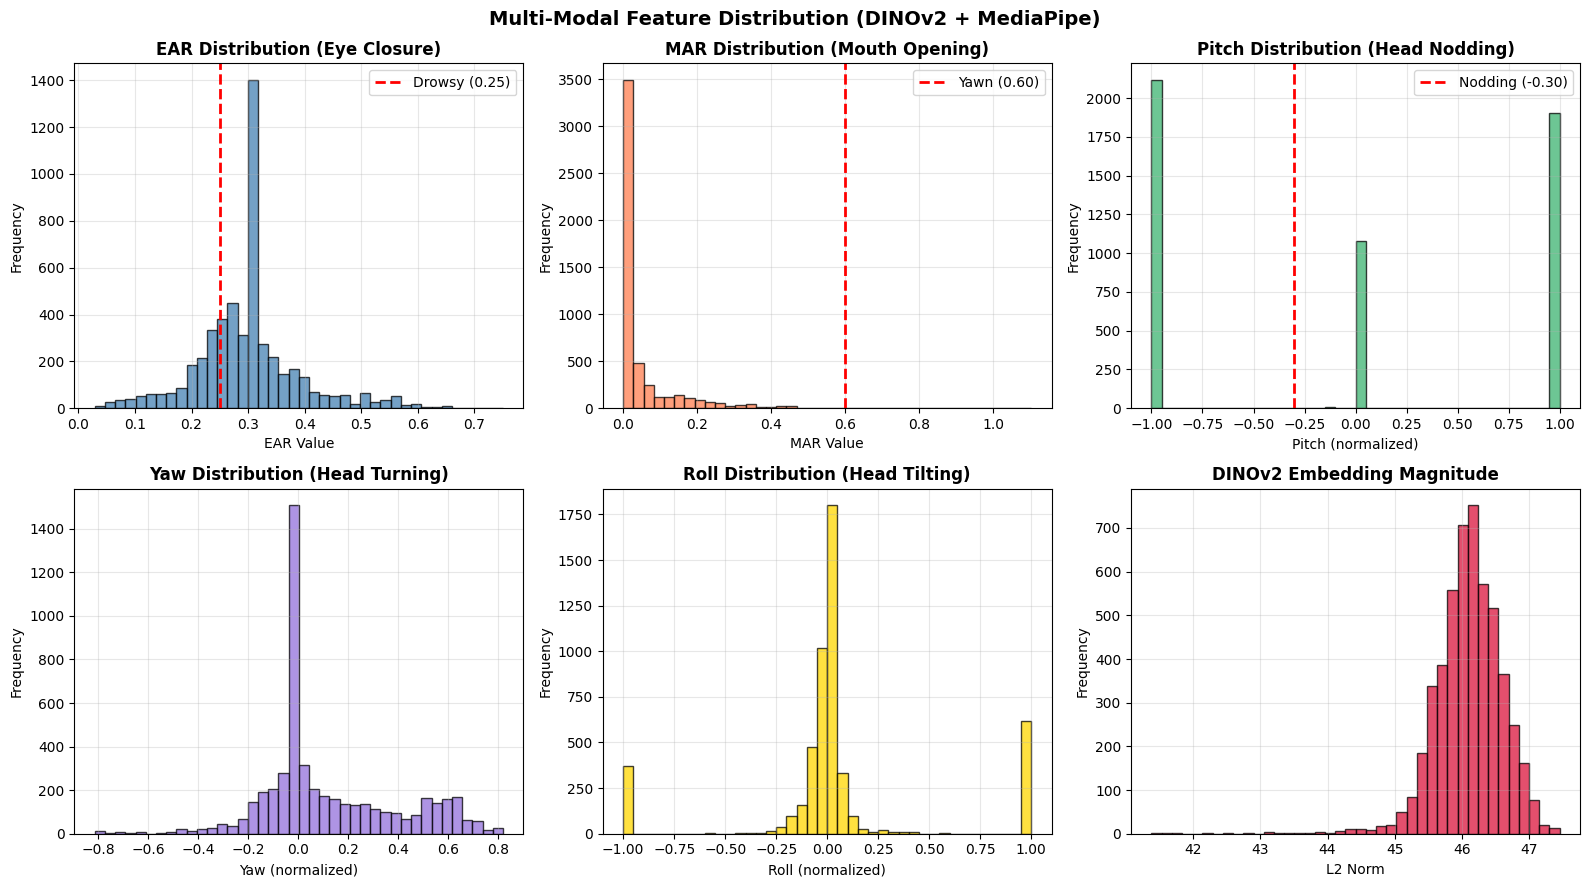

In [29]:
# EDA

# Ambil file .npy dari CONFIG.FEATURE_DIR
all_feature_files = glob.glob(os.path.join(CONFIG.FEATURE_DIR, "*.npy"))

if not all_feature_files:
    print(f"Tidak ditemukan file .npy di: {CONFIG.FEATURE_DIR}")
else:
    print(f"Memuat {len(all_feature_files)} file .npy untuk analisis distribusi...")

    # Load langsung ke satu matrix (N, 32, 1029)
    all_feats = np.stack([np.load(f) for f in all_feature_files], axis=0)

    # Slice fitur visual dan geometris
    visual_feats = all_feats[:, :, :1024]  # (N, 32, 1024)
    geo_feats    = all_feats[:, :, 1024:]  # (N, 32, 5)

    # Visualisasi Distribusi Fitur Geometris & L2 Norm DINOv2
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    # EAR distribution
    axes[0, 0].hist(geo_feats[:, :, 0].ravel(), bins=40, color='steelblue', alpha=0.75, edgecolor='black')
    axes[0, 0].axvline(0.25, color='red', linestyle='--', linewidth=2, label='Drowsy (0.25)')
    axes[0, 0].set_title('EAR Distribution (Eye Closure)', fontweight='bold')
    axes[0, 0].set_xlabel('EAR Value')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    # MAR distribution
    axes[0, 1].hist(geo_feats[:, :, 1].ravel(), bins=40, color='coral', alpha=0.75, edgecolor='black')
    axes[0, 1].axvline(0.60, color='red', linestyle='--', linewidth=2, label='Yawn (0.60)')
    axes[0, 1].set_title('MAR Distribution (Mouth Opening)', fontweight='bold')
    axes[0, 1].set_xlabel('MAR Value')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    # Pitch distribution (Nodding)
    axes[0, 2].hist(geo_feats[:, :, 2].ravel(), bins=40, color='mediumseagreen', alpha=0.75, edgecolor='black')
    axes[0, 2].axvline(-0.30, color='red', linestyle='--', linewidth=2, label='Nodding (-0.30)')
    axes[0, 2].set_title('Pitch Distribution (Head Nodding)', fontweight='bold')
    axes[0, 2].set_xlabel('Pitch (normalized)')
    axes[0, 2].set_ylabel('Frequency')
    axes[0, 2].legend()
    axes[0, 2].grid(alpha=0.3)

    # Yaw distribution (Turning)
    axes[1, 0].hist(geo_feats[:, :, 3].ravel(), bins=40, color='mediumpurple', alpha=0.75, edgecolor='black')
    axes[1, 0].set_title('Yaw Distribution (Head Turning)', fontweight='bold')
    axes[1, 0].set_xlabel('Yaw (normalized)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].grid(alpha=0.3)

    # Roll distribution (Tilting)
    axes[1, 1].hist(geo_feats[:, :, 4].ravel(), bins=40, color='gold', alpha=0.75, edgecolor='black')
    axes[1, 1].set_title('Roll Distribution (Head Tilting)', fontweight='bold')
    axes[1, 1].set_xlabel('Roll (normalized)')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].grid(alpha=0.3)

    # DINOv2 L2 Norm
    visual_norms = np.linalg.norm(visual_feats, axis=2).ravel()
    axes[1, 2].hist(visual_norms, bins=40, color='crimson', alpha=0.75, edgecolor='black')
    axes[1, 2].set_title('DINOv2 Embedding Magnitude', fontweight='bold')
    axes[1, 2].set_xlabel('L2 Norm')
    axes[1, 2].set_ylabel('Frequency')
    axes[1, 2].grid(alpha=0.3)

    plt.suptitle('Multi-Modal Feature Distribution (DINOv2 + MediaPipe)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [30]:
# Manual Split & Cross-Validation Strategy

# HOLD-OUT TEST SET (Subject-Independent: Subjek 16-20)
test_subjects = [f"subject_{i:02d}" for i in range(16, 21)]

df_testing = df_features[df_features['subject'].isin(test_subjects)].reset_index(drop=True)
df_training = df_features[~df_features['subject'].isin(test_subjects)].reset_index(drop=True)

print("STEP 1: Hold-out Subject Split")
print(f"   • Train/Val Pool : {len(df_training)} sampel | {df_training['subject'].nunique()} subjek")
print(f"   • Final Test Set : {len(df_testing)} sampel | {df_testing['subject'].nunique()} subjek")

# GROUP K-FOLD (Mencegah Data Leakage Antar Subjek)
n_groups = df_training['subject'].nunique()
actual_folds = min(CONFIG.FOLDS, n_groups) if n_groups > 1 else 1

if actual_folds > 1:
    gkf = GroupKFold(n_splits=actual_folds)
    folds = list(gkf.split(
        X=df_training['feature_path'].values,  # Menggunakan path .npy
        y=df_training['label'].values,
        groups=df_training['subject'].values
    ))

    print(f"\nSTEP 2: GroupKFold Distribution ({actual_folds} Folds)\n")
    for fold_idx, (train_idx, val_idx) in enumerate(folds):
        fold_train_df = df_training.iloc[train_idx]
        fold_val_df   = df_training.iloc[val_idx]

        train_dist = fold_train_df['label'].value_counts()
        val_dist   = fold_val_df['label'].value_counts()

        print(f"Fold {fold_idx + 1}:")
        print(f"   Train : {len(train_idx)} sampel | {fold_train_df['subject'].nunique()} subjek "
              f"(Drowsy: {train_dist.get(1, 0)}, Non-Drowsy: {train_dist.get(0, 0)})")
        print(f"   Val   : {len(val_idx)} sampel | {fold_val_df['subject'].nunique()} subjek "
              f"(Drowsy: {val_dist.get(1, 0)}, Non-Drowsy: {val_dist.get(0, 0)})")
        print(f"   Val Subjects: {sorted(fold_val_df['subject'].unique())}\n")
else:
    print("\nCatatan: Jumlah subjek training saat ini < 2, GroupKFold membutuhkan minimal 2 subjek.")
    folds = []

print("Cross-validation setup complete. Siap lanjut ke training loop!")

STEP 1: Hold-out Subject Split
   • Train/Val Pool : 120 sampel | 15 subjek
   • Final Test Set : 40 sampel | 5 subjek

STEP 2: GroupKFold Distribution (5 Folds)

Fold 1:
   Train : 96 sampel | 12 subjek (Drowsy: 48, Non-Drowsy: 48)
   Val   : 24 sampel | 3 subjek (Drowsy: 12, Non-Drowsy: 12)
   Val Subjects: ['subject_05', 'subject_10', 'subject_15']

Fold 2:
   Train : 96 sampel | 12 subjek (Drowsy: 48, Non-Drowsy: 48)
   Val   : 24 sampel | 3 subjek (Drowsy: 12, Non-Drowsy: 12)
   Val Subjects: ['subject_04', 'subject_09', 'subject_14']

Fold 3:
   Train : 96 sampel | 12 subjek (Drowsy: 48, Non-Drowsy: 48)
   Val   : 24 sampel | 3 subjek (Drowsy: 12, Non-Drowsy: 12)
   Val Subjects: ['subject_03', 'subject_08', 'subject_13']

Fold 4:
   Train : 96 sampel | 12 subjek (Drowsy: 48, Non-Drowsy: 48)
   Val   : 24 sampel | 3 subjek (Drowsy: 12, Non-Drowsy: 12)
   Val Subjects: ['subject_02', 'subject_07', 'subject_12']

Fold 5:
   Train : 96 sampel | 12 subjek (Drowsy: 48, Non-Drowsy: 48)

In [31]:
class TrainingConfig:
    # Optimizer Hyperparameters
    INIT_LR         = 1e-4
    WEIGHT_DECAY    = 1e-2
    BETAS           = (0.9, 0.999)
    EPS             = 1e-8
    LABEL_SMOOTHING = 0.1

    # Training Schedule & Early Stopping
    EPOCHS          = 50
    T_0             = 10
    ETA_MIN         = 1e-6
    PATIENCE        = 15
    MIN_DELTA       = 0.001

    # Hardware Acceleration
    USE_AMP         = torch.cuda.is_available()

TRAIN_CONFIG = TrainingConfig()

print("Training configuration locked:")
print(f"   • Max Epochs      : {TRAIN_CONFIG.EPOCHS}")
print(f"   • Learning Rate   : {TRAIN_CONFIG.INIT_LR} (CosineAnnealing T_0={TRAIN_CONFIG.T_0})")
print(f"   • Regularization  : Label Smoothing={TRAIN_CONFIG.LABEL_SMOOTHING}, Weight Decay={TRAIN_CONFIG.WEIGHT_DECAY}")
print(f"   • Early Stopping  : Patience={TRAIN_CONFIG.PATIENCE}, Min Delta={TRAIN_CONFIG.MIN_DELTA}")
print(f"   • Mixed Precision : {'Enabled (FP16)' if TRAIN_CONFIG.USE_AMP else 'Disabled (FP32)'}")

Training configuration locked:
   • Max Epochs      : 50
   • Learning Rate   : 0.0001 (CosineAnnealing T_0=10)
   • Regularization  : Label Smoothing=0.1, Weight Decay=0.01
   • Early Stopping  : Patience=15, Min Delta=0.001
   • Mixed Precision : Disabled (FP32)


In [32]:
# Baseline

# Hyperparameter khusus arsitektur baseline klasik
BASELINE_HIDDEN_DIM = 128
BASELINE_DROPOUT = 0.3
BASELINE_EPOCHS = 50
NUM_CLASSES = getattr(CONFIG, "NUM_CLASSES", 2)

# Baseline 1: Simple RNN
class SimpleRNN(nn.Module):
    def __init__(self, input_dim=CONFIG.INPUT_DIM, hidden_dim=BASELINE_HIDDEN_DIM, dropout=BASELINE_DROPOUT):
        super().__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=dropout)
        self.fc  = nn.Linear(hidden_dim, NUM_CLASSES)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

# Baseline 2: Simple LSTM
class SimpleLSTM(nn.Module):
    def __init__(self, input_dim=CONFIG.INPUT_DIM, hidden_dim=BASELINE_HIDDEN_DIM, dropout=BASELINE_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=dropout)
        self.fc   = nn.Linear(hidden_dim, NUM_CLASSES)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# Baseline 3: 1D-CNN (Temporal Convolutional)
class SimpleCNN1D(nn.Module):
    def __init__(self, input_dim=CONFIG.INPUT_DIM, hidden_dim=BASELINE_HIDDEN_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, hidden_dim, kernel_size=3, padding=1),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.fc = nn.Linear(hidden_dim, NUM_CLASSES)

    def forward(self, x):
        x = x.transpose(1, 2)  # (Batch, 1029, 32)
        x = self.conv(x).squeeze(-1)
        return self.fc(x)

# Factory Function
def get_baseline_model(model_type):
    model_type = str(model_type).upper()
    if model_type == "RNN":
        return SimpleRNN().to(CONFIG.DEVICE)
    elif model_type == "LSTM":
        return SimpleLSTM().to(CONFIG.DEVICE)
    elif model_type == "CNN":
        return SimpleCNN1D().to(CONFIG.DEVICE)
    else:
        raise ValueError(f"Model type '{model_type}' tidak valid. Pilih: 'RNN', 'LSTM', atau 'CNN'.")

# Statistik Parameter Baseline
models_dict = {
    "SimpleRNN": SimpleRNN(),
    "SimpleLSTM": SimpleLSTM(),
    "SimpleCNN1D": SimpleCNN1D()
}

print("STATISTIK MODEL BASELINE PEMBANDING")
for name, model in models_dict.items():
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = (trainable_params * 4) / (1024 * 1024)
    print(f"{name:<15} | Trainable Params: {trainable_params:>10,} | Size: ~{size_mb:.2f} MB")

STATISTIK MODEL BASELINE PEMBANDING
SimpleRNN       | Trainable Params:    181,634 | Size: ~0.69 MB
SimpleLSTM      | Trainable Params:    725,762 | Size: ~2.77 MB
SimpleCNN1D     | Trainable Params:    222,978 | Size: ~0.85 MB


In [33]:
# Training Function

def train_fold(model_type, fold_idx, train_idx, val_idx):
    model_type = model_type.upper()
    print(f"\nSTARTING FOLD {fold_idx + 1} | MODEL: {model_type}")

    train_df = df_training.iloc[train_idx].reset_index(drop=True)
    val_df   = df_training.iloc[val_idx].reset_index(drop=True)

    # Dataset & DataLoader
    train_ds = DrowsinessFeatureDataset(train_df['feature_path'].values, train_df['label'].values, augment=True)
    val_ds   = DrowsinessFeatureDataset(val_df['feature_path'].values,   val_df['label'].values,   augment=False)

    batch_size = min(CONFIG.BATCH_SIZE, len(train_ds))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=0, drop_last=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)

    # Inisialisasi Model, Optimizer & Scheduler
    model     = get_baseline_model(model_type)
    optimizer = optim.AdamW(model.parameters(), lr=TRAIN_CONFIG.INIT_LR, weight_decay=TRAIN_CONFIG.WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss(label_smoothing=TRAIN_CONFIG.LABEL_SMOOTHING)
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=TRAIN_CONFIG.T_0, eta_min=TRAIN_CONFIG.ETA_MIN
    )
    
    use_cuda = (CONFIG.DEVICE.type == 'cuda') if isinstance(CONFIG.DEVICE, torch.device) else (CONFIG.DEVICE == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=(use_cuda and TRAIN_CONFIG.USE_AMP))

    history = {'train_loss': [], 'val_loss': [], 'val_recall': []}
    best_val_recall = 0.0

    for epoch in range(BASELINE_EPOCHS):
        # Training Phase
        model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad()

            with torch.amp.autocast('cuda', enabled=(use_cuda and TRAIN_CONFIG.USE_AMP)):
                outputs = model(feats)
                loss    = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        # Validation Phase
        model.eval()
        v_loss = 0.0
        preds, targets = [], []
        with torch.no_grad():
            for feats, labels in val_loader:
                feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
                with torch.amp.autocast('cuda', enabled=(use_cuda and TRAIN_CONFIG.USE_AMP)):
                    outputs = model(feats)
                    loss    = criterion(outputs, labels)

                v_loss += loss.item()
                p = torch.argmax(outputs, dim=1)
                preds.extend(p.cpu().numpy())
                targets.extend(labels.cpu().numpy())

        avg_t_loss = t_loss / max(len(train_loader), 1)
        avg_v_loss = v_loss / max(len(val_loader), 1)
        
        # Evaluasi Macro Recall
        v_recall = recall_score(targets, preds, average='macro', zero_division=0)

        history['train_loss'].append(avg_t_loss)
        history['val_loss'].append(avg_v_loss)
        history['val_recall'].append(v_recall)

        # Simpan checkpoint berdasarkan Macro Recall terbaik
        if v_recall > best_val_recall:
            best_val_recall = v_recall
            save_path = os.path.join(CONFIG.OUTPUT_DIR, f"best_{model_type.lower()}_fold{fold_idx + 1}.pth")
            torch.save(model.state_dict(), save_path)
            print(f"   Ep {epoch+1:02d} | T-Loss: {avg_t_loss:.4f} | V-Loss: {avg_v_loss:.4f} | Val Recall: {v_recall:.4f}")

        scheduler.step()

    print(f"Fold {fold_idx + 1} Selesai. Best Recall: {best_val_recall:.4f}")
    return best_val_recall, history

print("Training function ready")

Training function ready


# BASELINE (RNN, LSTM, CNN)

TRAINING BASELINE MODELS (RNN, LSTM, CNN-1D)...

TRAINING: RNN

STARTING FOLD 1 | MODEL: RNN
   Ep 01 | T-Loss: 0.6808 | V-Loss: 0.6866 | Val Recall: 0.5417
   Ep 02 | T-Loss: 0.6882 | V-Loss: 0.6798 | Val Recall: 0.5833
   Ep 04 | T-Loss: 0.6446 | V-Loss: 0.6715 | Val Recall: 0.6667
   Ep 08 | T-Loss: 0.6286 | V-Loss: 0.6634 | Val Recall: 0.7083
   Ep 23 | T-Loss: 0.5321 | V-Loss: 0.6333 | Val Recall: 0.7500
Fold 1 Selesai. Best Recall: 0.7500

STARTING FOLD 2 | MODEL: RNN
   Ep 01 | T-Loss: 0.7165 | V-Loss: 0.7175 | Val Recall: 0.4583
   Ep 03 | T-Loss: 0.6923 | V-Loss: 0.7099 | Val Recall: 0.5000
   Ep 18 | T-Loss: 0.6006 | V-Loss: 0.6970 | Val Recall: 0.5417
Fold 2 Selesai. Best Recall: 0.5417

STARTING FOLD 3 | MODEL: RNN
   Ep 01 | T-Loss: 0.7332 | V-Loss: 0.6804 | Val Recall: 0.5417
   Ep 02 | T-Loss: 0.6702 | V-Loss: 0.6748 | Val Recall: 0.6250
   Ep 03 | T-Loss: 0.6868 | V-Loss: 0.6717 | Val Recall: 0.6667
   Ep 04 | T-Loss: 0.6682 | V-Loss: 0.6681 | Val Recall: 0.7083
Fold 3 

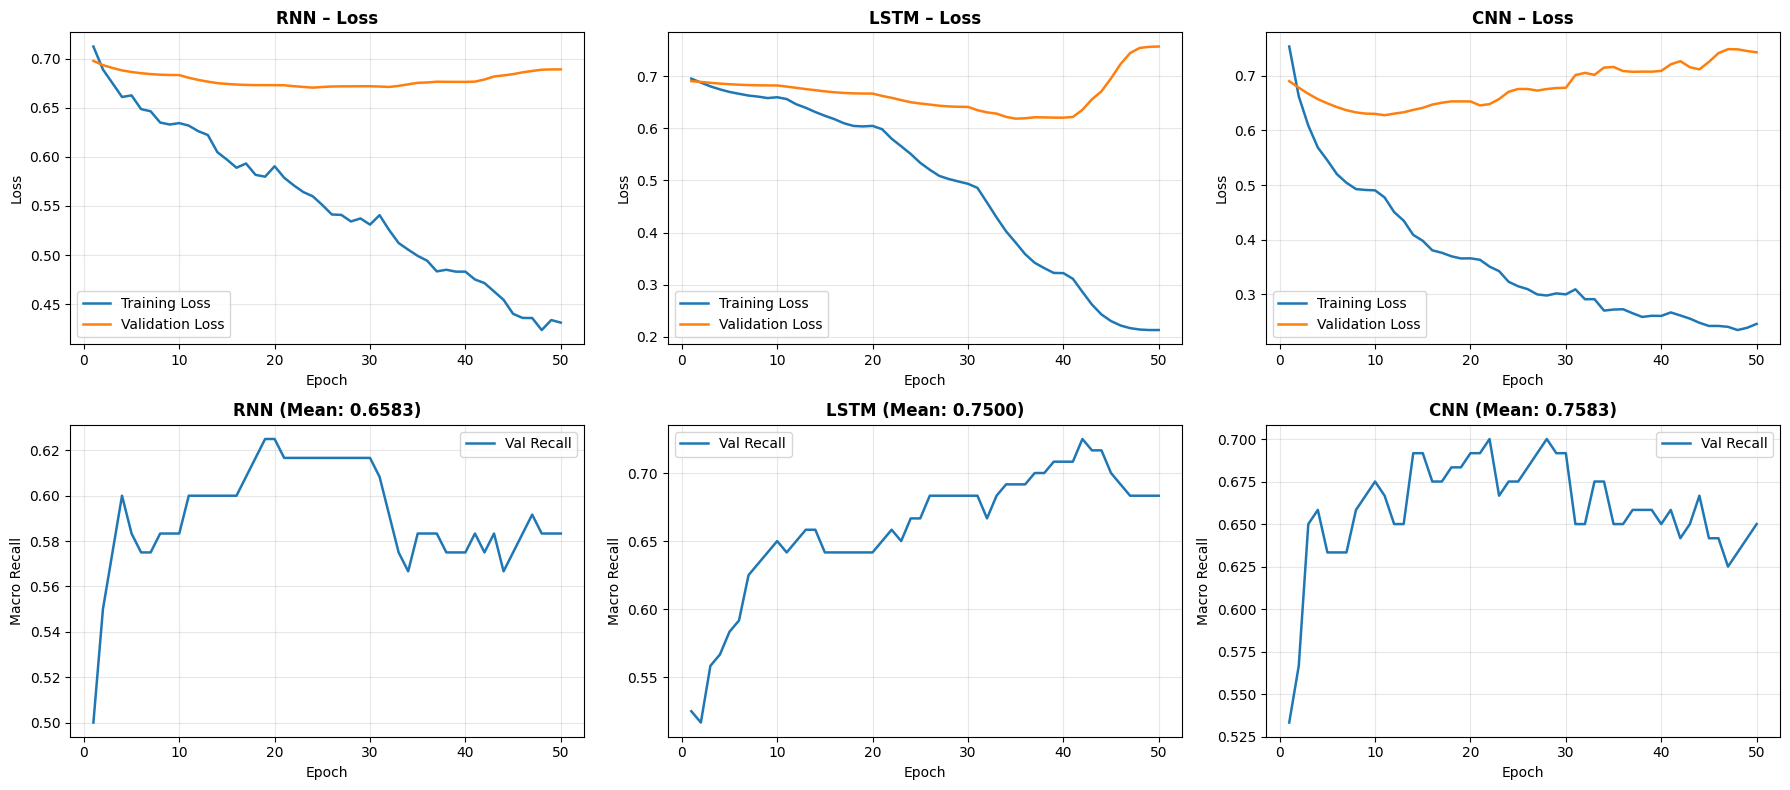

,Model,Mean Recall (CV)
0,CNN1D,0.758333
1,LSTM,0.750000
2,RNN,0.658333


In [34]:
# Training Baseline

baseline_models = ["RNN", "LSTM", "CNN"]
master_histories = []
summary_results  = []

print("TRAINING BASELINE MODELS (RNN, LSTM, CNN-1D)...")

for model_name in baseline_models:
    seed_everything(CONFIG.SEED)

    # Validasi pembagian fold
    n_groups = df_training['subject'].nunique()
    actual_folds = min(CONFIG.FOLDS, n_groups) if n_groups > 1 else 1

    if actual_folds > 1:
        gkf = GroupKFold(n_splits=actual_folds)
        folds = list(gkf.split(
            X=df_training['feature_path'].values,
            y=df_training['label'].values,
            groups=df_training['subject'].values
        ))
    else:
        # Fallback jika data subjek masih sedikit untuk testing
        folds = [(np.arange(len(df_training)), np.arange(len(df_training)))]

    model_t_loss   = []
    model_v_loss   = []
    model_recall   = []
    fold_scores    = []

    print(f"\nTRAINING: {model_name}")

    for i, (t_idx, v_idx) in enumerate(folds):
        score, history = train_fold(model_name, i, t_idx, v_idx)

        fold_scores.append(score)
        model_t_loss.append(history['train_loss'])
        model_v_loss.append(history['val_loss'])
        # Mengambil histori val_recall dari dictionary fold
        model_recall.append(history.get('val_recall', history.get('val_f1')))

    mean_recall = float(np.mean(fold_scores))

    master_histories.append({
        'model': model_name,
        't_loss': np.mean(model_t_loss, axis=0),
        'v_loss': np.mean(model_v_loss, axis=0),
        'recall': np.mean(model_recall, axis=0),
        'final_recall': mean_recall
    })

    summary_results.append({
        'Model': f"{model_name.upper() if model_name != 'CNN' else 'CNN1D'}",
        'Mean Recall (CV)': mean_recall
    })

# VISUALISASI TRAINING DYNAMICS BASELINE (PERSIS SEPERTI FORMAT AWAL)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 8))

for i, res in enumerate(master_histories):
    name = res['model'].upper() if res['model'] != 'CNN' else 'CNN'
    epochs_range = range(1, len(res['t_loss']) + 1)

    # Baris 1: Kurva Loss (Solid Blue & Solid Orange)
    axes[0, i].plot(epochs_range, res['t_loss'], label='Training Loss', color='#1f77b4', linewidth=1.8)
    axes[0, i].plot(epochs_range, res['v_loss'], label='Validation Loss', color='#ff7f0e', linewidth=1.8)
    axes[0, i].set_title(f"{name} – Loss", fontweight='bold', fontsize=12)
    axes[0, i].set_xlabel('Epoch')
    axes[0, i].set_ylabel('Loss')
    axes[0, i].legend()
    axes[0, i].grid(True, alpha=0.3)

    # Baris 2: Kurva Val Recall (Solid Blue & Judul Mean)
    axes[1, i].plot(epochs_range, res['recall'], label='Val Recall', color='#1f77b4', linewidth=1.8)
    axes[1, i].set_title(f"{name} (Mean: {res['final_recall']:.4f})", fontweight='bold', fontsize=12)
    axes[1, i].set_xlabel('Epoch')
    axes[1, i].set_ylabel('Macro Recall')
    axes[1, i].legend()
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# TABEL PERBANDINGAN BASELINE BERDASARKAN RECALL
df_summary = pd.DataFrame(summary_results).sort_values(by='Mean Recall (CV)', ascending=False).reset_index(drop=True)
display(df_summary)

GLOBAL TESTING: EVALUASI BASELINE MODEL PADA TEST SET (SUBJECT 16-20)

Evaluating Model: RNN...

Evaluating Model: LSTM...

Evaluating Model: CNN...

RINGKASAN EVALUASI MODEL BASELINE


,Model,Accuracy,Precision,Recall,Macro F1,Latency (ms),FPS,Masker,Kacamata Putih,Kacamata Hitam,Normal (Polos),Topi
0,RNN,0.5250,0.5251,0.5250,0.5247,3.59,278.7,50.0%,75.0%,37.5%,37.5%,62.5%
1,LSTM,0.5500,0.5549,0.5500,0.5396,8.27,120.9,50.0%,75.0%,50.0%,50.0%,50.0%
2,CNN1D,0.8750,0.8836,0.8750,0.8743,4.28,233.5,62.5%,100.0%,87.5%,100.0%,87.5%


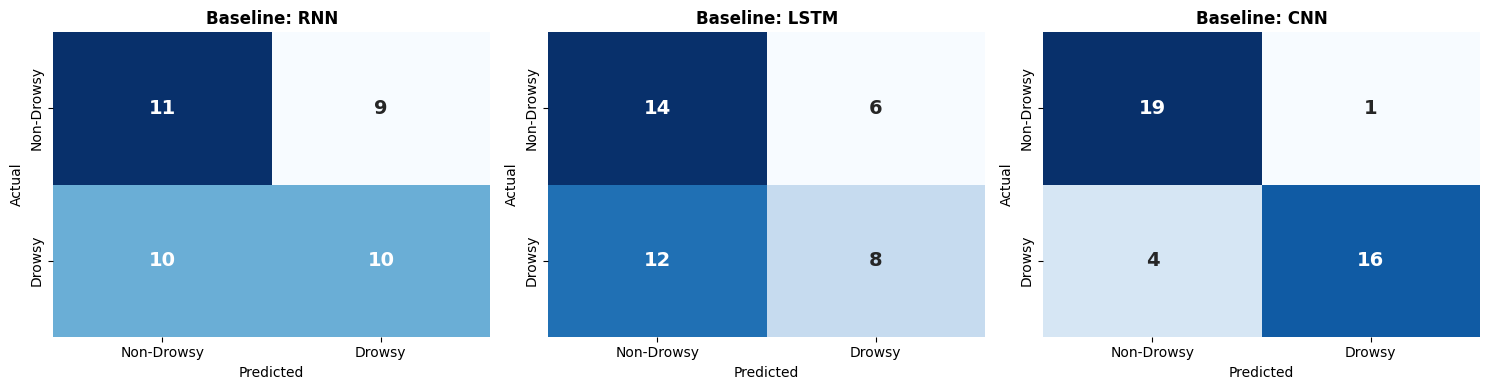

In [ ]:
# Final Testing on Hidden Subjects (16-20)

def run_final_benchmark_testing():
    if len(df_testing) == 0:
        print("Data df_testing kosong (subjek 16-20 belum tersedia di dataset). Pengujian dilewati.")
        return

    print("GLOBAL TESTING: EVALUASI BASELINE MODEL PADA TEST SET (SUBJECT 16-20)")

    model_names = ["RNN", "LSTM", "CNN"]
    labels_text = ["Non-Drowsy", "Drowsy"]
    attr_map = {
        'subject_16': 'Masker',
        'subject_17': 'Kacamata Putih',
        'subject_18': 'Kacamata Hitam',
        'subject_19': 'Normal (Polos)',
        'subject_20': 'Topi'
    }

    all_model_benchmarks   = []
    all_confusion_matrices = []

    # Setup DataLoader untuk Hold-out Test Set
    test_ds     = DrowsinessFeatureDataset(df_testing['feature_path'].values, df_testing['label'].values, augment=False)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

    for name in model_names:
        print(f"\nEvaluating Model: {name}...")
        
        # Panggil fungsi inisialisasi model (support get_baseline_model atau build_baseline_model)
        if 'get_baseline_model' in globals():
            model = get_baseline_model(name).to(CONFIG.DEVICE)
        else:
            model = build_baseline_model(name).to(CONFIG.DEVICE)

        # 1. Cek path utama di folder result/models
        pth_path = os.path.join(CONFIG.OUTPUT_DIR, f"best_{name.lower()}_fold1.pth")
        
        # 2. Fallback cek root directory jika belum terpindah
        if not os.path.exists(pth_path):
            fallback_path = f"best_{name.lower()}_fold1.pth"
            if os.path.exists(fallback_path):
                pth_path = fallback_path
            else:
                print(f"   Checkpoint {pth_path} tidak ditemukan. Skip model {name}.")
                continue

        model.load_state_dict(torch.load(pth_path, map_location=CONFIG.DEVICE))
        model.eval()

        all_preds, all_targets = [], []
        results_per_attr = {attr: {'correct': 0, 'total': 0} for attr in attr_map.values()}
        inference_times  = []

        # Warm-up pass
        if isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda":
            warmup_feat, _ = next(iter(test_loader))
            with torch.no_grad():
                _ = model(warmup_feat.to(CONFIG.DEVICE))
            torch.cuda.synchronize()

        with torch.no_grad():
            for i, (feats, labels) in enumerate(test_loader):
                feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)

                if isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                start = time.perf_counter()
                
                outputs = model(feats)
                
                if isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                inference_times.append(time.perf_counter() - start)

                pred   = torch.argmax(outputs, dim=1).item()
                target = labels.item()

                # Breakdown per atribut subjek
                current_subject = df_testing.iloc[i]['subject']
                attr_name = attr_map.get(current_subject, "Unknown")
                if attr_name in results_per_attr:
                    if pred == target:
                        results_per_attr[attr_name]['correct'] += 1
                    results_per_attr[attr_name]['total'] += 1

                all_preds.append(pred)
                all_targets.append(target)

        # Perhitungan Metrik Evaluasi
        acc       = accuracy_score(all_targets, all_preds)
        prec      = precision_score(all_targets, all_preds, average='macro', zero_division=0)
        rec       = recall_score(all_targets, all_preds, average='macro', zero_division=0)
        f1        = f1_score(all_targets, all_preds, average='macro', zero_division=0)
        cm        = confusion_matrix(all_targets, all_preds)
        avg_infer = np.mean(inference_times)

        all_confusion_matrices.append((name, cm))

        res_entry = {
            'Model': f"{name if name != 'CNN' else 'CNN1D'}",
            'Accuracy': f"{acc:.4f}",
            'Precision': f"{prec:.4f}",
            'Recall': f"{rec:.4f}",
            'Macro F1': f"{f1:.4f}",
            'Latency (ms)': f"{avg_infer * 1000:.2f}",
            'FPS': f"{1 / avg_infer:.1f}" if avg_infer > 0 else "N/A"
        }

        # Breakdown akurasi per atribut kondisi khusus
        for attr, stats in results_per_attr.items():
            if stats['total'] > 0:
                attr_acc = (stats['correct'] / stats['total']) * 100
                res_entry[attr] = f"{attr_acc:.1f}%"

        all_model_benchmarks.append(res_entry)

    # Tampilkan Ringkasan Evaluasi
    if all_model_benchmarks:
        print("\nRINGKASAN EVALUASI MODEL BASELINE")
        df_final = pd.DataFrame(all_model_benchmarks)
        display(df_final)

        # Visualisasi Confusion Matrix
        n = len(all_confusion_matrices)
        fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
        if n == 1:
            axes = [axes]

        for i, (name, cm) in enumerate(all_confusion_matrices):
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                        xticklabels=labels_text, yticklabels=labels_text,
                        annot_kws={"size": 14, "weight": "bold"})
            axes[i].set_title(f"Baseline: {name}", fontsize=12, fontweight='bold')
            axes[i].set_xlabel("Predicted")
            axes[i].set_ylabel("Actual")

        plt.tight_layout()
        plt.show()

run_final_benchmark_testing()

# TRANSFORMER TEACHER MODEL


STARTING TEACHER FOLD 1
   Ep 01 | T-Loss: 0.7641 | V-Loss: 0.6777 | Val Recall: 0.5000
   Ep 03 | T-Loss: 0.6919 | V-Loss: 0.6558 | Val Recall: 0.7917
   Ep 07 | T-Loss: 0.5464 | V-Loss: 0.3954 | Val Recall: 0.8333
   Ep 08 | T-Loss: 0.4733 | V-Loss: 0.3703 | Val Recall: 0.9167
   Ep 20 | T-Loss: 0.3237 | V-Loss: 0.1258 | Val Recall: 1.0000

STARTING TEACHER FOLD 2
   Ep 01 | T-Loss: 0.8195 | V-Loss: 0.7137 | Val Recall: 0.5000
   Ep 06 | T-Loss: 0.6682 | V-Loss: 0.6697 | Val Recall: 0.5833
   Ep 08 | T-Loss: 0.5560 | V-Loss: 0.6389 | Val Recall: 0.7500

STARTING TEACHER FOLD 3
   Ep 01 | T-Loss: 0.7870 | V-Loss: 0.6981 | Val Recall: 0.5000
   Ep 02 | T-Loss: 0.6981 | V-Loss: 0.6878 | Val Recall: 0.5833
   Ep 07 | T-Loss: 0.5465 | V-Loss: 0.6523 | Val Recall: 0.7083
   Ep 12 | T-Loss: 0.2890 | V-Loss: 0.7777 | Val Recall: 0.7500
   Ep 13 | T-Loss: 0.2254 | V-Loss: 0.6208 | Val Recall: 0.7917

STARTING TEACHER FOLD 4
   Ep 01 | T-Loss: 0.7961 | V-Loss: 0.6884 | Val Recall: 0.5000
   E

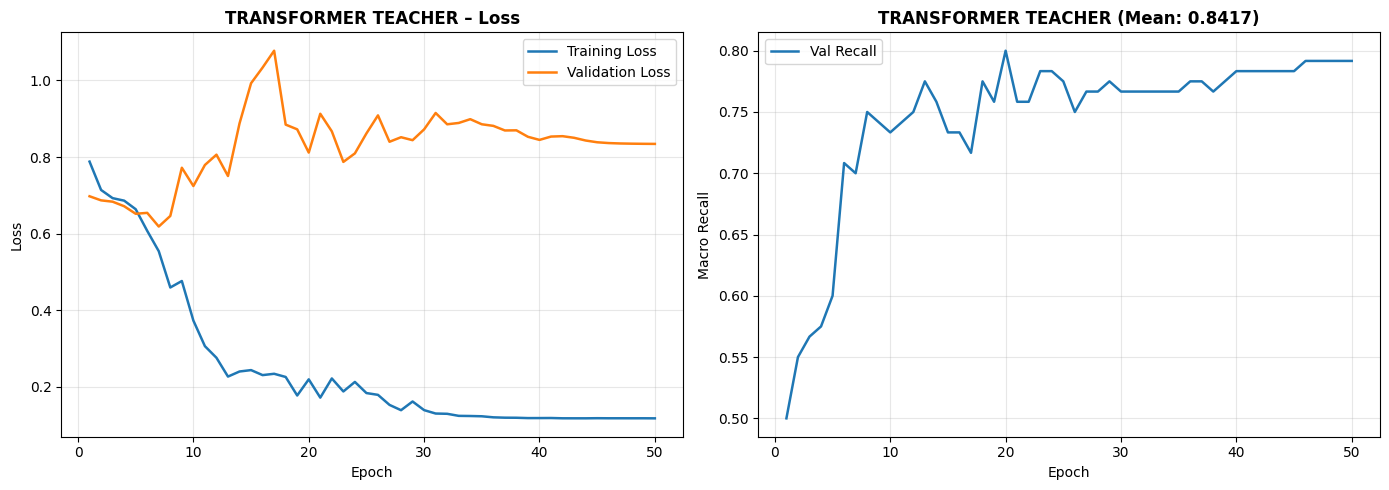


TRAINING FINAL TEACHER MODEL (14 Epochs)...
Final Teacher Model tersimpan di: c:\Users\User\SKRIPSI\result\models\best_teacher_telup_final.pth


In [37]:
# TEACHER TRAINING & VALIDATION DYNAMICS

# ARSITEKTUR TRANSFORMER TEACHER
class TransformerTeacher(nn.Module):
    def __init__(self, 
                 input_dim=CONFIG.INPUT_DIM, 
                 hidden_dim=CONFIG.TEACHER_HIDDEN_DIM,
                 num_layers=CONFIG.TEACHER_LAYERS, 
                 num_heads=CONFIG.TEACHER_HEADS,
                 ffn_dim=CONFIG.TEACHER_FFN, 
                 dropout=CONFIG.DROPOUT):
        super().__init__()
        self.norm_in = nn.LayerNorm(input_dim)
        self.project = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pos_embed = nn.Parameter(torch.randn(1, CONFIG.SEQ_LEN, hidden_dim) * 0.02)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=ffn_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.final_norm  = nn.LayerNorm(hidden_dim)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, CONFIG.TEACHER_CLASSIFIER_DIM),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(CONFIG.TEACHER_CLASSIFIER_DIM, CONFIG.NUM_CLASSES)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.size(0)
        x = self.norm_in(x)
        x = self.project(x) + self.pos_embed
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.transformer(x)
        cls_out = self.final_norm(x[:, 0, :])
        return self.classifier(cls_out)

# TRAINING & VALIDASI PER FOLD
def train_teacher_fold(fold_idx, train_idx, val_idx, df_pool):
    print(f"\nSTARTING TEACHER FOLD {fold_idx + 1}")
    train_df = df_pool.iloc[train_idx].reset_index(drop=True)
    val_df   = df_pool.iloc[val_idx].reset_index(drop=True)

    train_ds = DrowsinessFeatureDataset(train_df["feature_path"].values, train_df["label"].values, augment=True)
    val_ds   = DrowsinessFeatureDataset(val_df["feature_path"].values, val_df["label"].values, augment=False)

    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=CONFIG.NUM_WORKERS, drop_last=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=CONFIG.NUM_WORKERS)

    model = TransformerTeacher().to(CONFIG.DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS, eta_min=CONFIG.MIN_LR)
    criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    history = {"train_loss": [], "val_loss": [], "val_recall": []}
    best_recall, best_epoch = -1.0, 0
    fold_weight_path = os.path.join(CONFIG.OUTPUT_DIR, f"best_teacher_telup_fold{fold_idx + 1}.pth")

    for epoch in range(CONFIG.EPOCHS):
        model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                outputs = model(feats)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        # Validasi
        model.eval()
        v_loss = 0.0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for feats, labels in val_loader:
                feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
                with torch.amp.autocast("cuda", enabled=use_cuda):
                    outputs = model(feats)
                    loss = criterion(outputs, labels)
                v_loss += loss.item()
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        avg_t_loss = t_loss / max(len(train_loader), 1)
        avg_v_loss = v_loss / max(len(val_loader), 1)
        val_rec    = recall_score(val_targets, val_preds, average="macro", zero_division=0)

        history["train_loss"].append(avg_t_loss)
        history["val_loss"].append(avg_v_loss)
        history["val_recall"].append(val_rec)

        if val_rec > best_recall:
            best_recall, best_epoch = val_rec, epoch + 1
            torch.save(model.state_dict(), fold_weight_path)
            print(f"   Ep {epoch+1:02d} | T-Loss: {avg_t_loss:.4f} | V-Loss: {avg_v_loss:.4f} | Val Recall: {val_rec:.4f}")

        scheduler.step()

    return best_recall, best_epoch, fold_weight_path, history

# TRAINING FINAL TEACHER MODEL
def train_final_teacher(df_pool, epochs):
    print(f"\nTRAINING FINAL TEACHER MODEL ({epochs} Epochs)...")
    seed_everything(CONFIG.SEED)

    train_ds = DrowsinessFeatureDataset(df_pool["feature_path"].values, df_pool["label"].values, augment=True)
    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=CONFIG.NUM_WORKERS)

    model = TransformerTeacher().to(CONFIG.DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=CONFIG.MIN_LR)
    criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    for epoch in range(epochs):
        model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                outputs = model(feats)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        scheduler.step()

    torch.save(model.state_dict(), CONFIG.TEACHER_WEIGHT_PATH)
    print(f"Final Teacher Model tersimpan di: {CONFIG.TEACHER_WEIGHT_PATH}")
    return CONFIG.TEACHER_WEIGHT_PATH

# EKSEKUSI PIPELINE TEACHER CROSS-VALIDATION
seed_everything(CONFIG.SEED)
teacher_scores, teacher_best_epochs = [], []
teacher_t_loss, teacher_v_loss, teacher_recall = [], [], []

for i, (t_idx, v_idx) in enumerate(folds):
    rec, ep, _, hist = train_teacher_fold(i, t_idx, v_idx, df_training)
    teacher_scores.append(rec)
    teacher_best_epochs.append(ep)
    teacher_t_loss.append(hist["train_loss"])
    teacher_v_loss.append(hist["val_loss"])
    teacher_recall.append(hist["val_recall"])

mean_teacher_recall = float(np.mean(teacher_scores))
median_teacher_epoch = max(int(np.median(teacher_best_epochs)), 1)
print(f"\nTeacher CV Mean Recall: {mean_teacher_recall:.4f} ± {np.std(teacher_scores):.4f} (Median Epoch: {median_teacher_epoch})")

# Rata-rata kurva fold untuk visualisasi
avg_teacher_t_loss = np.mean(teacher_t_loss, axis=0)
avg_teacher_v_loss = np.mean(teacher_v_loss, axis=0)
avg_teacher_rec    = np.mean(teacher_recall, axis=0)

# VISUALISASI TRAINING DYNAMICS TEACHER
epochs_range = range(1, len(avg_teacher_t_loss) + 1)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Subplot 1: Loss Dynamics
axes[0].plot(epochs_range, avg_teacher_t_loss, label='Training Loss', color='#1f77b4', linewidth=1.8)
axes[0].plot(epochs_range, avg_teacher_v_loss, label='Validation Loss', color='#ff7f0e', linewidth=1.8)
axes[0].set_title("TRANSFORMER TEACHER – Loss", fontweight='bold', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Subplot 2: Validation Recall Dynamics
axes[1].plot(epochs_range, avg_teacher_rec, label='Val Recall', color='#1f77b4', linewidth=1.8)
axes[1].set_title(f"TRANSFORMER TEACHER (Mean: {mean_teacher_recall:.4f})", fontweight='bold', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro Recall')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Retraining Model Final Teacher
final_teacher_path = train_final_teacher(df_training, epochs=median_teacher_epoch)

FINAL TESTING: TRANSFORMER TEACHER PADA TEST SET (SUBJECT 16–20)
Model berhasil dimuat dari: c:\Users\User\SKRIPSI\result\models\best_teacher_telup_final.pth
Cross-Validation Ref: Best CV Recall = 1.0000 (Fold 1 | Epoch: 20)

HASIL TESTING FINAL TEACHER:


,Model,Test Acc,Test Prec,Test Rec,Test F1,Inference (ms),FPS,Masker,Kacamata Putih,Kacamata Hitam,Normal (Polos),Topi
0,Transformer Teacher,0.9250,0.9261,0.9250,0.9250,149.12,6.7,87.5%,100.0%,87.5%,100.0%,87.5%


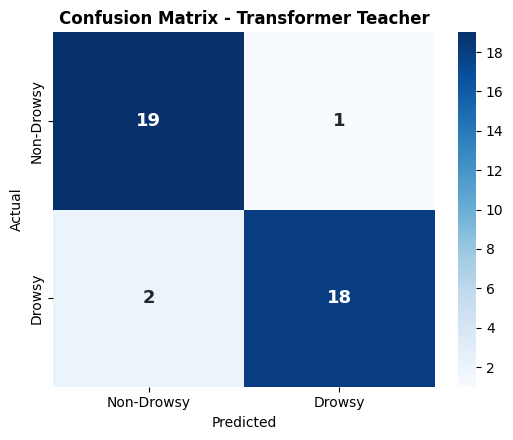

In [ ]:
# Testing Teacher Model

def run_final_testing_teacher(
    model_path=CONFIG.TEACHER_WEIGHT_PATH,
    cv_scores=None,
    best_epochs=None
):
    if len(df_testing) == 0:
        print("Data df_testing kosong (subjek 16-20 belum tersedia). Pengujian dilewati.")
        return None, None

    print(f"FINAL TESTING: TRANSFORMER TEACHER PADA TEST SET (SUBJECT 16–20)")

    labels_text = ["Non-Drowsy", "Drowsy"]
    attr_map = {
        'subject_16': 'Masker',
        'subject_17': 'Kacamata Putih',
        'subject_18': 'Kacamata Hitam',
        'subject_19': 'Normal (Polos)',
        'subject_20': 'Topi'
    }

    # Setup DataLoader Testing
    test_ds = DrowsinessFeatureDataset(df_testing['feature_path'].values, df_testing['label'].values, augment=False)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Checkpoint model tidak ditemukan di: {model_path}")

    # Load Model Weights
    model = TransformerTeacher().to(CONFIG.DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=CONFIG.DEVICE))
    model.eval()
    print(f"Model berhasil dimuat dari: {model_path}")

    # Info Ringkas CV 
    if cv_scores is not None:
        best_cv_idx = int(np.argmax(cv_scores))
        best_ep = f" | Epoch: {best_epochs[best_cv_idx]}" if best_epochs is not None else ""
        print(f"Cross-Validation Ref: Best CV Recall = {cv_scores[best_cv_idx]:.4f} (Fold {best_cv_idx + 1}{best_ep})")

    all_preds, all_targets = [], []
    inference_times = []
    results_per_attr = {attr: {'correct': 0, 'total': 0} for attr in attr_map.values()}

    # Warm-up GPU
    if CONFIG.DEVICE == "cuda":
        warmup_feat, _ = next(iter(test_loader))
        with torch.no_grad():
            _ = model(warmup_feat.to(CONFIG.DEVICE))
        torch.cuda.synchronize()

    # Evaluasi Inference
    with torch.no_grad():
        for i, (feats, labels) in enumerate(test_loader):
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)

            if CONFIG.DEVICE == "cuda":
                torch.cuda.synchronize()
            start_time = time.perf_counter()

            outputs = model(feats)

            if CONFIG.DEVICE == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start_time

            inference_times.append(elapsed)

            pred   = torch.argmax(outputs, dim=1).item()
            target = labels.item()

            all_preds.append(pred)
            all_targets.append(target)

            subj_id = df_testing.iloc[i]['subject']
            attr_name = attr_map.get(subj_id, "Unknown")
            if attr_name in results_per_attr:
                results_per_attr[attr_name]['total'] += 1
                if pred == target:
                    results_per_attr[attr_name]['correct'] += 1

    # Metrik Evaluasi
    test_acc  = accuracy_score(all_targets, all_preds)
    test_prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    test_rec  = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    test_f1   = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    cm        = confusion_matrix(all_targets, all_preds)
    avg_infer = np.mean(inference_times)
    fps       = 1 / avg_infer if avg_infer > 0 else 0

    result = {
        'Model': 'Transformer Teacher',
        'Test Acc': f'{test_acc:.4f}',
        'Test Prec': f'{test_prec:.4f}',
        'Test Rec': f'{test_rec:.4f}',
        'Test F1': f'{test_f1:.4f}',
        'Inference (ms)': f'{avg_infer * 1000:.2f}',
        'FPS': f'{fps:.1f}'
    }

    for attr, stats in results_per_attr.items():
        if stats['total'] > 0:
            result[attr] = f"{(stats['correct'] / stats['total']) * 100:.1f}%"

    df_final = pd.DataFrame([result])
    print("\nHASIL TESTING FINAL TEACHER:")
    display(df_final)

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels_text, yticklabels=labels_text,
                annot_kws={"size": 13, "weight": "bold"})
    plt.title("Confusion Matrix - Transformer Teacher", fontsize=12, fontweight='bold')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return df_final, cm

# Eksekusi Testing
df_test_teacher, cm_teacher = run_final_testing_teacher(
    model_path=final_teacher_path,
    cv_scores=teacher_scores,
    best_epochs=teacher_best_epochs
)

# TRANSFORMER STUDENT MODEL

Transformer Student Parameters: 1,559,852 (~5.95 MB)

STARTING STUDENT FOLD 1
   Ep 01 | T-Loss: 0.6981 | V-Loss: 0.6887 | Val Recall: 0.5000 (Saved)
   Ep 02 | T-Loss: 0.6902 | V-Loss: 0.6862 | Val Recall: 0.7083 (Saved)
   Ep 06 | T-Loss: 0.6728 | V-Loss: 0.6580 | Val Recall: 0.7917 (Saved)
   Ep 09 | T-Loss: 0.6231 | V-Loss: 0.5949 | Val Recall: 0.8750 (Saved)
   Ep 19 | T-Loss: 0.3858 | V-Loss: 0.4125 | Val Recall: 0.9167 (Saved)

STARTING STUDENT FOLD 2
   Ep 01 | T-Loss: 0.6982 | V-Loss: 0.6918 | Val Recall: 0.5417 (Saved)
   Ep 02 | T-Loss: 0.6880 | V-Loss: 0.6890 | Val Recall: 0.6667 (Saved)
   Ep 03 | T-Loss: 0.6866 | V-Loss: 0.6847 | Val Recall: 0.7500 (Saved)
   Ep 05 | T-Loss: 0.6757 | V-Loss: 0.6678 | Val Recall: 0.7917 (Saved)
   Ep 06 | T-Loss: 0.6571 | V-Loss: 0.6552 | Val Recall: 0.8333 (Saved)

STARTING STUDENT FOLD 3
   Ep 01 | T-Loss: 0.6955 | V-Loss: 0.6922 | Val Recall: 0.5000 (Saved)
   Ep 03 | T-Loss: 0.6905 | V-Loss: 0.6891 | Val Recall: 0.6250 (Saved)
   Ep 04

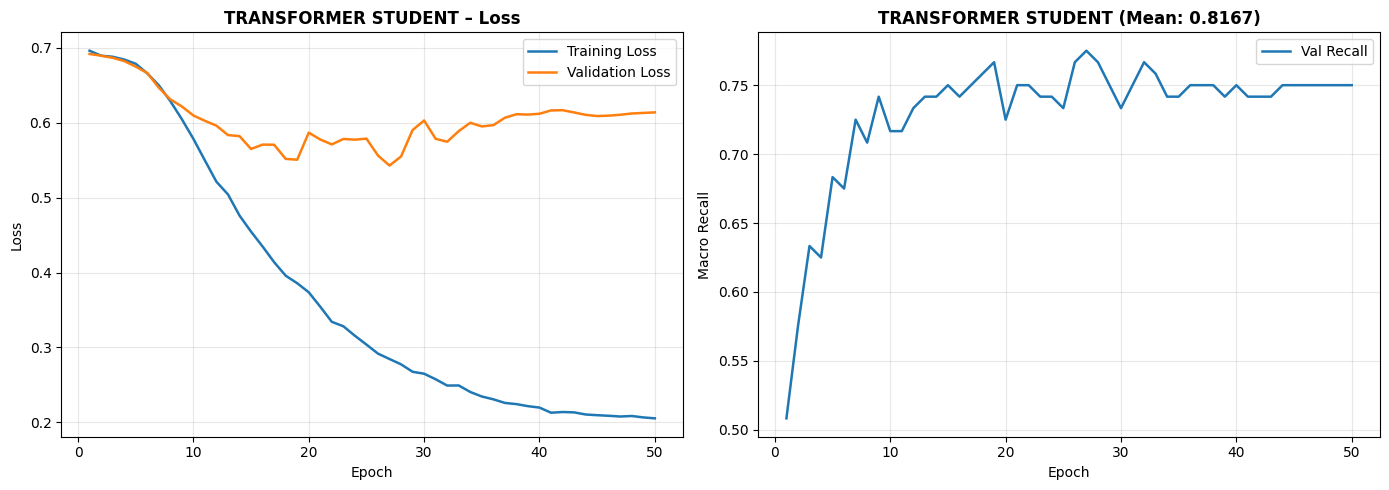


TRAINING FINAL STUDENT BASELINE (15 Epochs)...
Final Student Baseline tersimpan di: c:\Users\User\SKRIPSI\result\models\best_student_baseline_telup_final.pth


In [ ]:
# Training Student

# ARSITEKTUR TRANSFORMER STUDENT
class TransformerStudent(nn.Module):
    def __init__(self, 
                 input_dim=CONFIG.INPUT_DIM, 
                 hidden_dim=CONFIG.STUDENT_HIDDEN_DIM,
                 num_layers=CONFIG.STUDENT_LAYERS, 
                 num_heads=CONFIG.STUDENT_HEADS,
                 ffn_dim=CONFIG.STUDENT_FFN, 
                 dropout=CONFIG.DROPOUT):
        super().__init__()
        self.norm_in = nn.LayerNorm(input_dim)
        self.project = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pos_embed = nn.Parameter(torch.randn(1, CONFIG.SEQ_LEN, hidden_dim) * 0.02)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=ffn_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.final_norm  = nn.LayerNorm(hidden_dim)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, CONFIG.STUDENT_CLASSIFIER_DIM),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(CONFIG.STUDENT_CLASSIFIER_DIM, CONFIG.NUM_CLASSES)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.size(0)
        x = self.norm_in(x)
        x = self.project(x) + self.pos_embed
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.transformer(x)
        cls_out = self.final_norm(x[:, 0, :])
        return self.classifier(cls_out)

# STATISTIK PARAMETER STUDENT
sample_student = TransformerStudent()
total_student_params = sum(p.numel() for p in sample_student.parameters())
trainable_student_params = sum(p.numel() for p in sample_student.parameters() if p.requires_grad)
print(f"Transformer Student Parameters: {total_student_params:,} (~{total_student_params * 4 / (1024*1024):.2f} MB)")

# TRAINING FUNCTION PER FOLD
def train_student_fold(fold_idx, train_idx, val_idx, df_pool):
    print(f"\nSTARTING STUDENT FOLD {fold_idx + 1}")
    train_df = df_pool.iloc[train_idx].reset_index(drop=True)
    val_df   = df_pool.iloc[val_idx].reset_index(drop=True)

    train_ds = DrowsinessFeatureDataset(train_df["feature_path"].values, train_df["label"].values, augment=True)
    val_ds   = DrowsinessFeatureDataset(val_df["feature_path"].values, val_df["label"].values, augment=False)

    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=CONFIG.NUM_WORKERS, drop_last=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=CONFIG.NUM_WORKERS)

    model = TransformerStudent().to(CONFIG.DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS, eta_min=CONFIG.MIN_LR)
    criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    history = {"train_loss": [], "val_loss": [], "val_recall": []}
    best_recall, best_epoch = -1.0, 0
    fold_weight_path = os.path.join(CONFIG.OUTPUT_DIR, f"best_student_baseline_fold{fold_idx + 1}.pth")

    for epoch in range(CONFIG.EPOCHS):
        model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                outputs = model(feats)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        # Validasi
        model.eval()
        v_loss = 0.0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for feats, labels in val_loader:
                feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
                with torch.amp.autocast("cuda", enabled=use_cuda):
                    outputs = model(feats)
                    loss = criterion(outputs, labels)
                v_loss += loss.item()
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        avg_t_loss = t_loss / max(len(train_loader), 1)
        avg_v_loss = v_loss / max(len(val_loader), 1)
        val_rec    = recall_score(val_targets, val_preds, average="macro", zero_division=0)

        history["train_loss"].append(avg_t_loss)
        history["val_loss"].append(avg_v_loss)
        history["val_recall"].append(val_rec)

        if val_rec > best_recall:
            best_recall, best_epoch = val_rec, epoch + 1
            torch.save(model.state_dict(), fold_weight_path)
            print(f"   Ep {epoch+1:02d} | T-Loss: {avg_t_loss:.4f} | V-Loss: {avg_v_loss:.4f} | Val Recall: {val_rec:.4f} (Saved)")

        scheduler.step()

    return best_recall, best_epoch, fold_weight_path, history

# TRAINING FINAL STUDENT BASELINE PADA SEMUA TRAINING POOL
def train_final_student(df_pool, epochs):
    print(f"\nTRAINING FINAL STUDENT BASELINE ({epochs} Epochs)...")
    seed_everything(CONFIG.SEED)

    train_ds = DrowsinessFeatureDataset(df_pool["feature_path"].values, df_pool["label"].values, augment=True)
    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=CONFIG.NUM_WORKERS)

    model = TransformerStudent().to(CONFIG.DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=CONFIG.MIN_LR)
    criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    for epoch in range(epochs):
        model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                outputs = model(feats)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        scheduler.step()

    torch.save(model.state_dict(), CONFIG.STUDENT_BASELINE_WEIGHT_PATH)
    print(f"Final Student Baseline tersimpan di: {CONFIG.STUDENT_BASELINE_WEIGHT_PATH}")
    return CONFIG.STUDENT_BASELINE_WEIGHT_PATH

# EKSEKUSI PIPELINE STUDENT CROSS-VALIDATION
seed_everything(CONFIG.SEED)
student_scores, student_best_epochs = [], []
student_t_loss, student_v_loss, student_recall = [], [], []

for i, (t_idx, v_idx) in enumerate(folds):
    rec, ep, _, hist = train_student_fold(i, t_idx, v_idx, df_training)
    student_scores.append(rec)
    student_best_epochs.append(ep)
    student_t_loss.append(hist["train_loss"])
    student_v_loss.append(hist["val_loss"])
    student_recall.append(hist["val_recall"])

mean_student_recall  = float(np.mean(student_scores))
median_student_epoch = max(int(np.median(student_best_epochs)), 1)
print(f"\nStudent CV Mean Recall: {mean_student_recall:.4f} ± {np.std(student_scores):.4f} (Median Epoch: {median_student_epoch})")

# Rata-rata kurva fold untuk visualisasi
avg_student_t_loss = np.mean(student_t_loss, axis=0)
avg_student_v_loss = np.mean(student_v_loss, axis=0)
avg_student_rec    = np.mean(student_recall, axis=0)

# VISUALISASI TRAINING DYNAMICS STUDENT BASELINE
epochs_range = range(1, len(avg_student_t_loss) + 1)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Subplot 1: Loss Dynamics
axes[0].plot(epochs_range, avg_student_t_loss, label='Training Loss', color='#1f77b4', linewidth=1.8)
axes[0].plot(epochs_range, avg_student_v_loss, label='Validation Loss', color='#ff7f0e', linewidth=1.8)
axes[0].set_title("TRANSFORMER STUDENT – Loss", fontweight='bold', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Subplot 2: Validation Recall Dynamics
axes[1].plot(epochs_range, avg_student_rec, label='Val Recall', color='#1f77b4', linewidth=1.8)
axes[1].set_title(f"TRANSFORMER STUDENT (Mean: {mean_student_recall:.4f})", fontweight='bold', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro Recall')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Retraining Model Final Student
final_student_path = train_final_student(df_training, epochs=median_student_epoch)

FINAL TESTING: TRANSFORMER STUDENT (BASELINE) PADA TEST SET (SUBJECT 16–20)
Model Student berhasil dimuat dari: c:\Users\User\SKRIPSI\result\models\best_student_baseline_telup_final.pth
Cross-Validation Ref: Best CV Recall = 0.9167 (Fold 1 | Epoch: 19)

HASIL TESTING FINAL STUDENT:


,Model,Test Acc,Test Prec,Test Rec,Test F1,Inference (ms),FPS,Masker,Kacamata Putih,Kacamata Hitam,Normal (Polos),Topi
0,Transformer Student (Baseline),0.8750,0.8836,0.8750,0.8743,10.57,94.6,62.5%,100.0%,75.0%,100.0%,100.0%


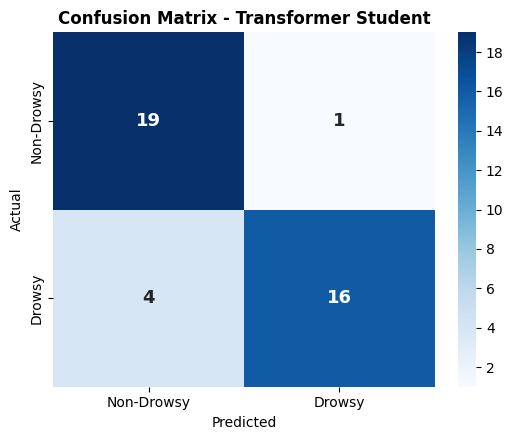

In [42]:
# Testing Student Model

def run_final_testing_student(
    model_path=CONFIG.STUDENT_BASELINE_WEIGHT_PATH,
    cv_scores=None,
    best_epochs=None
):
    if len(df_testing) == 0:
        print("Data df_testing kosong (subjek 16-20 belum tersedia). Pengujian dilewati.")
        return None, None

    print(f"FINAL TESTING: TRANSFORMER STUDENT (BASELINE) PADA TEST SET (SUBJECT 16–20)")

    labels_text = ["Non-Drowsy", "Drowsy"]
    attr_map = {
        'subject_16': 'Masker',
        'subject_17': 'Kacamata Putih',
        'subject_18': 'Kacamata Hitam',
        'subject_19': 'Normal (Polos)',
        'subject_20': 'Topi'
    }

    test_ds = DrowsinessFeatureDataset(df_testing['feature_path'].values, df_testing['label'].values, augment=False)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Checkpoint model tidak ditemukan di: {model_path}")

    model = TransformerStudent().to(CONFIG.DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=CONFIG.DEVICE))
    model.eval()
    print(f"Model Student berhasil dimuat dari: {model_path}")

    if cv_scores is not None:
        best_cv_idx = int(np.argmax(cv_scores))
        best_ep = f" | Epoch: {best_epochs[best_cv_idx]}" if best_epochs is not None else ""
        print(f"Cross-Validation Ref: Best CV Recall = {cv_scores[best_cv_idx]:.4f} (Fold {best_cv_idx + 1}{best_ep})")

    all_preds, all_targets = [], []
    inference_times = []
    results_per_attr = {attr: {'correct': 0, 'total': 0} for attr in attr_map.values()}

    if CONFIG.DEVICE == "cuda":
        warmup_feat, _ = next(iter(test_loader))
        with torch.no_grad():
            _ = model(warmup_feat.to(CONFIG.DEVICE))
        torch.cuda.synchronize()

    with torch.no_grad():
        for i, (feats, labels) in enumerate(test_loader):
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)

            if CONFIG.DEVICE == "cuda":
                torch.cuda.synchronize()
            start_time = time.perf_counter()

            outputs = model(feats)

            if CONFIG.DEVICE == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start_time

            inference_times.append(elapsed)

            pred   = torch.argmax(outputs, dim=1).item()
            target = labels.item()

            all_preds.append(pred)
            all_targets.append(target)

            subj_id = df_testing.iloc[i]['subject']
            attr_name = attr_map.get(subj_id, "Unknown")
            if attr_name in results_per_attr:
                results_per_attr[attr_name]['total'] += 1
                if pred == target:
                    results_per_attr[attr_name]['correct'] += 1

    test_acc  = accuracy_score(all_targets, all_preds)
    test_prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    test_rec  = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    test_f1   = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    cm        = confusion_matrix(all_targets, all_preds)
    avg_infer = np.mean(inference_times)
    fps       = 1 / avg_infer if avg_infer > 0 else 0

    result = {
        'Model': 'Transformer Student (Baseline)',
        'Test Acc': f'{test_acc:.4f}',
        'Test Prec': f'{test_prec:.4f}',
        'Test Rec': f'{test_rec:.4f}',
        'Test F1': f'{test_f1:.4f}',
        'Inference (ms)': f'{avg_infer * 1000:.2f}',
        'FPS': f'{fps:.1f}'
    }

    for attr, stats in results_per_attr.items():
        if stats['total'] > 0:
            result[attr] = f"{(stats['correct'] / stats['total']) * 100:.1f}%"

    df_final = pd.DataFrame([result])
    print("\nHASIL TESTING FINAL STUDENT:")
    display(df_final)

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels_text, yticklabels=labels_text,
                annot_kws={"size": 13, "weight": "bold"})
    plt.title("Confusion Matrix - Transformer Student", fontsize=12, fontweight='bold')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return df_final, cm

# Eksekusi Testing Student Baseline
df_test_student, cm_student = run_final_testing_student(
    model_path=final_student_path,
    cv_scores=student_scores,
    best_epochs=student_best_epochs
)

# DISTILLATION + QUANTIZATION


STARTING STUDENT QAT + KD FOLD 1
   Ep 01 | T-Loss: 0.7570 | V-Loss: 0.6878 | Val Recall: 0.5000 (Saved)
   Ep 05 | T-Loss: 0.7286 | V-Loss: 0.6631 | Val Recall: 0.6667 (Saved)
   Ep 06 | T-Loss: 0.7129 | V-Loss: 0.6413 | Val Recall: 0.7917 (Saved)
   Ep 09 | T-Loss: 0.6282 | V-Loss: 0.5676 | Val Recall: 0.8750 (Saved)
   Ep 16 | T-Loss: 0.4890 | V-Loss: 0.4082 | Val Recall: 0.9583 (Saved)

STARTING STUDENT QAT + KD FOLD 2
   Ep 01 | T-Loss: 0.8243 | V-Loss: 0.6918 | Val Recall: 0.4583 (Saved)
   Ep 02 | T-Loss: 0.8103 | V-Loss: 0.6928 | Val Recall: 0.5000 (Saved)
   Ep 05 | T-Loss: 0.7932 | V-Loss: 0.6692 | Val Recall: 0.6667 (Saved)
   Ep 08 | T-Loss: 0.7180 | V-Loss: 0.6259 | Val Recall: 0.7083 (Saved)
   Ep 12 | T-Loss: 0.5671 | V-Loss: 0.5745 | Val Recall: 0.7500 (Saved)
   Ep 13 | T-Loss: 0.5543 | V-Loss: 0.5690 | Val Recall: 0.7917 (Saved)

STARTING STUDENT QAT + KD FOLD 3
   Ep 01 | T-Loss: 0.7833 | V-Loss: 0.6935 | Val Recall: 0.5000 (Saved)
   Ep 06 | T-Loss: 0.7404 | V-Loss

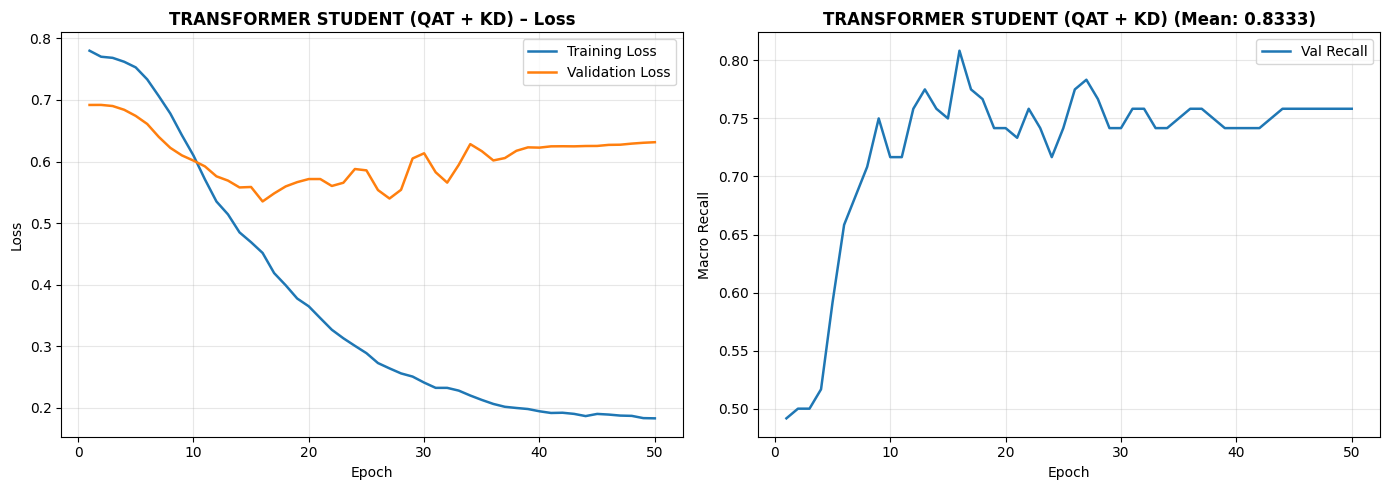


TRAINING FINAL STUDENT QAT + KD (13 Epochs)...
Final Model QAT + KD tersimpan di: c:\Users\User\SKRIPSI\result\models\best_student_qat_kd_telup_final.pth


In [43]:
# Training KD + QAT

# STRAIGHT-THROUGH ESTIMATOR (STE) FAKE QUANTIZATION INT8
class FakeQuantizeSTE(nn.Module):
    def __init__(self, bits=8):
        super().__init__()
        self.bits = bits
        self.qmin = -(2 ** (bits - 1))
        self.qmax = (2 ** (bits - 1)) - 1

    def forward(self, x):
        scale = torch.clamp(torch.max(torch.abs(x)) / self.qmax, min=1e-8)
        x_q = torch.clamp(torch.round(x / scale), self.qmin, self.qmax) * scale
        if not self.training:
            return x_q
        return (x_q - x).detach() + x

class QuantizedLinear(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features, bias=bias)
        self.weight_fake_quant = FakeQuantizeSTE(bits=8)
        self.act_fake_quant = FakeQuantizeSTE(bits=8)

    def forward(self, x):
        q_x = self.act_fake_quant(x)
        q_w = self.weight_fake_quant(self.linear.weight)
        return nn.functional.linear(q_x, q_w, self.linear.bias)

# ARSITEKTUR TRANSFORMER STUDENT QAT (STE)
class TransformerStudentQAT(nn.Module):
    def __init__(self, 
                 input_dim=CONFIG.INPUT_DIM, 
                 hidden_dim=CONFIG.STUDENT_HIDDEN_DIM,
                 num_layers=CONFIG.STUDENT_LAYERS, 
                 num_heads=CONFIG.STUDENT_HEADS,
                 ffn_dim=CONFIG.STUDENT_FFN, 
                 dropout=CONFIG.DROPOUT):
        super().__init__()
        self.norm_in = nn.LayerNorm(input_dim)
        self.project = nn.Sequential(
            QuantizedLinear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pos_embed = nn.Parameter(torch.randn(1, CONFIG.SEQ_LEN, hidden_dim) * 0.02)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=ffn_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.final_norm  = nn.LayerNorm(hidden_dim)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            QuantizedLinear(hidden_dim, CONFIG.STUDENT_CLASSIFIER_DIM),
            nn.GELU(),
            nn.Dropout(dropout),
            QuantizedLinear(CONFIG.STUDENT_CLASSIFIER_DIM, CONFIG.NUM_CLASSES)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.size(0)
        x = self.norm_in(x)
        x = self.project(x) + self.pos_embed
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.transformer(x)
        cls_out = self.final_norm(x[:, 0, :])
        return self.classifier(cls_out)

# LOSS DISTILASI PENGETAHUAN
class DistillationLoss(nn.Module):
    def __init__(self, temperature=CONFIG.TEMPERATURE, alpha=CONFIG.ALPHA, label_smoothing=CONFIG.LABEL_SMOOTHING):
        super().__init__()
        self.temperature = temperature
        self.alpha = alpha
        self.hard_criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.kl_div = nn.KLDivLoss(reduction="batchmean")

    def forward(self, student_logits, teacher_logits, labels):
        hard_loss = self.hard_criterion(student_logits, labels)
        soft_student = nn.functional.log_softmax(student_logits / self.temperature, dim=1)
        soft_teacher = nn.functional.softmax(teacher_logits / self.temperature, dim=1)
        soft_loss = self.kl_div(soft_student, soft_teacher) * (self.temperature ** 2)
        return (1.0 - self.alpha) * hard_loss + self.alpha * soft_loss

# TRAINING QAT+KD PER FOLD
def train_fold_student_qat_kd(fold_idx, train_idx, val_idx, df_pool, teacher_model):
    print(f"\nSTARTING STUDENT QAT + KD FOLD {fold_idx + 1}")
    train_df = df_pool.iloc[train_idx].reset_index(drop=True)
    val_df   = df_pool.iloc[val_idx].reset_index(drop=True)

    train_ds = DrowsinessFeatureDataset(train_df["feature_path"].values, train_df["label"].values, augment=True)
    val_ds   = DrowsinessFeatureDataset(val_df["feature_path"].values, val_df["label"].values, augment=False)

    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=CONFIG.NUM_WORKERS, drop_last=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=CONFIG.NUM_WORKERS)

    student_model = TransformerStudentQAT().to(CONFIG.DEVICE)
    teacher_model.eval()

    optimizer = optim.AdamW(student_model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS, eta_min=CONFIG.MIN_LR)
    distill_criterion = DistillationLoss(temperature=CONFIG.TEMPERATURE, alpha=CONFIG.ALPHA)
    val_criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    history = {"train_loss": [], "val_loss": [], "val_recall": []}
    best_recall, best_epoch = -1.0, 0
    fold_weight_path = os.path.join(CONFIG.OUTPUT_DIR, f"best_student_qat_kd_fold{fold_idx + 1}.pth")

    for epoch in range(CONFIG.EPOCHS):
        student_model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                teacher_outputs = teacher_model(feats)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                student_outputs = student_model(feats)
                loss = distill_criterion(student_outputs, teacher_outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(student_model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        # Validasi
        student_model.eval()
        v_loss = 0.0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for feats, labels in val_loader:
                feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
                with torch.amp.autocast("cuda", enabled=use_cuda):
                    outputs = student_model(feats)
                    loss = val_criterion(outputs, labels)
                v_loss += loss.item()
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        avg_t_loss = t_loss / max(len(train_loader), 1)
        avg_v_loss = v_loss / max(len(val_loader), 1)
        val_rec    = recall_score(val_targets, val_preds, average="macro", zero_division=0)

        history["train_loss"].append(avg_t_loss)
        history["val_loss"].append(avg_v_loss)
        history["val_recall"].append(val_rec)

        if val_rec > best_recall:
            best_recall, best_epoch = val_rec, epoch + 1
            torch.save(student_model.state_dict(), fold_weight_path)
            print(f"   Ep {epoch+1:02d} | T-Loss: {avg_t_loss:.4f} | V-Loss: {avg_v_loss:.4f} | Val Recall: {val_rec:.4f} (Saved)")

        scheduler.step()

    return best_recall, best_epoch, fold_weight_path, history

# RETRAINING FINAL MODEL PADA SELURUH TRAINING POOL
def train_final_student_qat_kd(df_pool, teacher_model, epochs):
    print(f"\nTRAINING FINAL STUDENT QAT + KD ({epochs} Epochs)...")
    seed_everything(CONFIG.SEED)

    train_ds = DrowsinessFeatureDataset(df_pool["feature_path"].values, df_pool["label"].values, augment=True)
    batch_size = min(CONFIG.BATCH_SIZE, max(len(train_ds), 1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=CONFIG.NUM_WORKERS)

    student_model = TransformerStudentQAT().to(CONFIG.DEVICE)
    teacher_model.eval()

    optimizer = optim.AdamW(student_model.parameters(), lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=CONFIG.MIN_LR)
    distill_criterion = DistillationLoss(temperature=CONFIG.TEMPERATURE, alpha=CONFIG.ALPHA)

    use_cuda = (CONFIG.DEVICE == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    for epoch in range(epochs):
        student_model.train()
        t_loss = 0.0
        for feats, labels in train_loader:
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                teacher_outputs = teacher_model(feats)

            with torch.amp.autocast("cuda", enabled=use_cuda):
                student_outputs = student_model(feats)
                loss = distill_criterion(student_outputs, teacher_outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(student_model.parameters(), CONFIG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        scheduler.step()

    torch.save(student_model.state_dict(), CONFIG.STUDENT_QAT_WEIGHT_PATH)
    print(f"Final Model QAT + KD tersimpan di: {CONFIG.STUDENT_QAT_WEIGHT_PATH}")
    return CONFIG.STUDENT_QAT_WEIGHT_PATH

# EKSEKUSI PIPELINE QAT + KD & VISUALISASI
teacher_model = TransformerTeacher().to(CONFIG.DEVICE)
teacher_model.load_state_dict(torch.load(CONFIG.TEACHER_WEIGHT_PATH, map_location=CONFIG.DEVICE))
teacher_model.eval()

seed_everything(CONFIG.SEED)
qat_scores, qat_best_epochs = [], []
qat_t_loss, qat_v_loss, qat_recall = [], [], []

for i, (t_idx, v_idx) in enumerate(folds):
    rec, ep, _, hist = train_fold_student_qat_kd(i, t_idx, v_idx, df_training, teacher_model)
    qat_scores.append(rec)
    qat_best_epochs.append(ep)
    qat_t_loss.append(hist["train_loss"])
    qat_v_loss.append(hist["val_loss"])
    qat_recall.append(hist["val_recall"])

mean_qat_recall  = float(np.mean(qat_scores))
median_qat_epoch = max(int(np.median(qat_best_epochs)), 1)
print(f"\nStudent QAT+KD CV Mean Recall: {mean_qat_recall:.4f} ± {np.std(qat_scores):.4f} (Median Epoch: {median_qat_epoch})")

# Rata-rata kurva fold untuk visualisasi
avg_qat_t_loss = np.mean(qat_t_loss, axis=0)
avg_qat_v_loss = np.mean(qat_v_loss, axis=0)
avg_qat_rec    = np.mean(qat_recall, axis=0)

# Visualisasi Training Dynamics
epochs_range = range(1, len(avg_qat_t_loss) + 1)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

axes[0].plot(epochs_range, avg_qat_t_loss, label='Training Loss', color='#1f77b4', linewidth=1.8)
axes[0].plot(epochs_range, avg_qat_v_loss, label='Validation Loss', color='#ff7f0e', linewidth=1.8)
axes[0].set_title("TRANSFORMER STUDENT (QAT + KD) – Loss", fontweight='bold', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, avg_qat_rec, label='Val Recall', color='#1f77b4', linewidth=1.8)
axes[1].set_title(f"TRANSFORMER STUDENT (QAT + KD) (Mean: {mean_qat_recall:.4f})", fontweight='bold', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro Recall')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Retraining Model Final
final_qat_path = train_final_student_qat_kd(df_training, teacher_model, epochs=median_qat_epoch)

FINAL TESTING: TRANSFORMER STUDENT (QAT + KD) PADA TEST SET (SUBJECT 16–20)

HASIL TESTING FINAL QAT + KD:


,Model,Test Acc,Test Prec,Test Rec,Test F1,Inference (ms),FPS,Masker,Kacamata Putih,Kacamata Hitam,Normal (Polos),Topi
0,Transformer Student (QAT + KD),0.9250,0.9261,0.9250,0.9250,12.44,80.4,87.5%,100.0%,75.0%,100.0%,100.0%


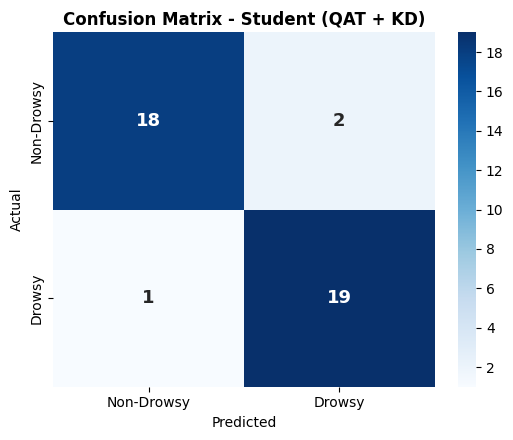

In [44]:
# Testing Student KD + QAT

def evaluate_final_qat_testing(model_path=CONFIG.STUDENT_QAT_WEIGHT_PATH):
    if len(df_testing) == 0:
        print("Data df_testing kosong. Pengujian dilewati.")
        return None, None

    print("FINAL TESTING: TRANSFORMER STUDENT (QAT + KD) PADA TEST SET (SUBJECT 16–20)")
    labels_text = ["Non-Drowsy", "Drowsy"]
    attr_map = {
        'subject_16': 'Masker',
        'subject_17': 'Kacamata Putih',
        'subject_18': 'Kacamata Hitam',
        'subject_19': 'Normal (Polos)',
        'subject_20': 'Topi'
    }

    test_ds = DrowsinessFeatureDataset(df_testing['feature_path'].values, df_testing['label'].values, augment=False)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

    eval_model = TransformerStudentQAT().to(CONFIG.DEVICE)
    eval_model.load_state_dict(torch.load(model_path, map_location=CONFIG.DEVICE))
    eval_model.eval()

    all_preds, all_targets = [], []
    inference_times = []
    results_per_attr = {attr: {'correct': 0, 'total': 0} for attr in attr_map.values()}

    # Warm-up pass
    if str(CONFIG.DEVICE) == "cuda" or (isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda"):
        warmup_feat, _ = next(iter(test_loader))
        with torch.no_grad():
            _ = eval_model(warmup_feat.to(CONFIG.DEVICE))
        torch.cuda.synchronize()

    with torch.no_grad():
        for i, (feats, labels) in enumerate(test_loader):
            feats, labels = feats.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)

            if str(CONFIG.DEVICE) == "cuda" or (isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda"):
                torch.cuda.synchronize()
            start_time = time.perf_counter()

            outputs = eval_model(feats)

            if str(CONFIG.DEVICE) == "cuda" or (isinstance(CONFIG.DEVICE, torch.device) and CONFIG.DEVICE.type == "cuda"):
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start_time

            inference_times.append(elapsed)

            pred   = torch.argmax(outputs, dim=1).item()
            target = labels.item()

            all_preds.append(pred)
            all_targets.append(target)

            subj_id = df_testing.iloc[i]['subject']
            attr_name = attr_map.get(subj_id, "Unknown")
            if attr_name in results_per_attr:
                results_per_attr[attr_name]['total'] += 1
                if pred == target:
                    results_per_attr[attr_name]['correct'] += 1

    test_acc  = accuracy_score(all_targets, all_preds)
    test_prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    test_rec  = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    test_f1   = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    cm        = confusion_matrix(all_targets, all_preds)
    avg_infer = np.mean(inference_times)
    fps       = 1 / avg_infer if avg_infer > 0 else 0

    result = {
        'Model': 'Transformer Student (QAT + KD)',
        'Test Acc': f'{test_acc:.4f}',
        'Test Prec': f'{test_prec:.4f}',
        'Test Rec': f'{test_rec:.4f}',
        'Test F1': f'{test_f1:.4f}',
        'Inference (ms)': f'{avg_infer * 1000:.2f}',
        'FPS': f'{fps:.1f}'
    }

    for attr, stats in results_per_attr.items():
        if stats['total'] > 0:
            result[attr] = f"{(stats['correct'] / stats['total']) * 100:.1f}%"

    df_final = pd.DataFrame([result])
    print("\nHASIL TESTING FINAL QAT + KD:")
    display(df_final)

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels_text, yticklabels=labels_text,
                annot_kws={"size": 13, "weight": "bold"})
    plt.title("Confusion Matrix - Student (QAT + KD)", fontsize=12, fontweight='bold')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return df_final, cm

# Eksekusi Evaluasi Testing
df_test_qat, cm_qat = evaluate_final_qat_testing(CONFIG.STUDENT_QAT_WEIGHT_PATH)

# EXPLAIN AI (ATTENTION MAPS)

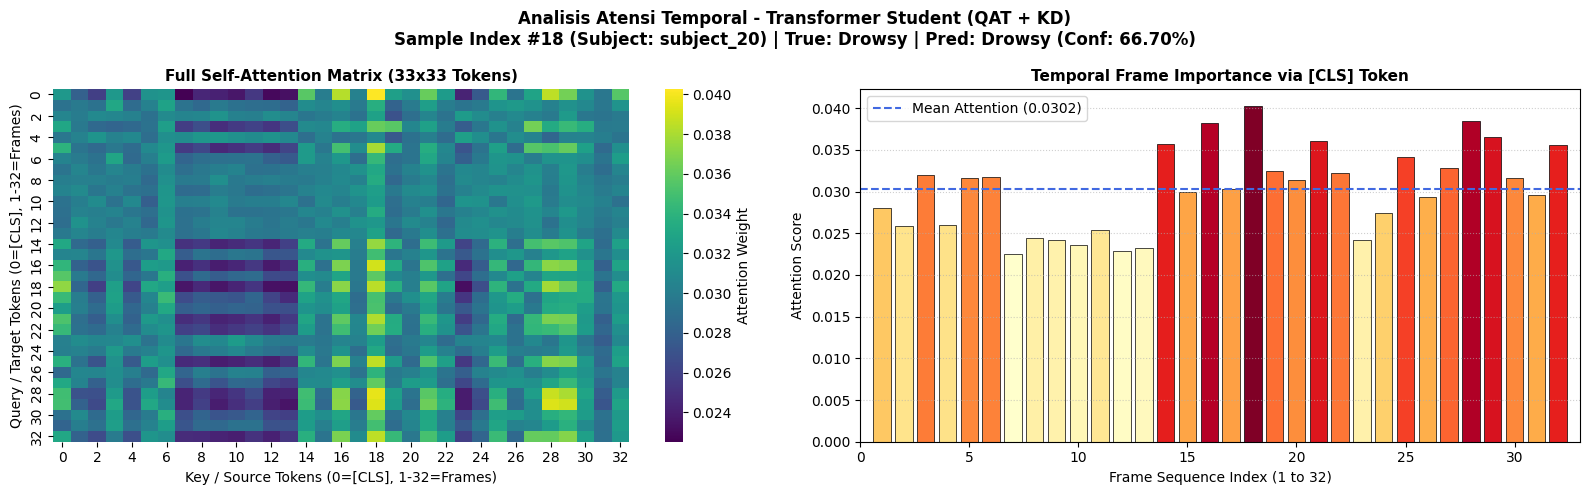

In [46]:
# Attention maps

# WRAPPER EKSTRAKSI ATTENTION WEIGHTS (URUTAN FORWARD IDENTIK DENGAN TRAINING)
class StudentQATAttentionExtractor:
    def __init__(self, model):
        self.model = model

    def get_attention_map(self, x):
        self.model.eval()
        B = x.size(0)

        with torch.no_grad():
            x = self.model.norm_in(x)
            # Tambahkan positional embedding ke 32 frame token 
            x = self.model.project(x) + self.model.pos_embed
            # 2 Gabungkan [CLS] token (32 -> 33 tokens)
            cls = self.model.cls_token.expand(B, -1, -1)
            x = torch.cat([cls, x], dim=1)

            # Forward layer encoder sebelum layer terakhir
            for layer in self.model.transformer.layers[:-1]:
                x = layer(x)

            # Ekstraksi attention weights pada layer terakhir
            last_layer = self.model.transformer.layers[-1]
            norm_x = last_layer.norm1(x) if getattr(last_layer, "norm_first", True) else x

            _, attn_weights = last_layer.self_attn(
                norm_x, norm_x, norm_x, need_weights=True, average_attn_weights=True
            )

        return attn_weights

# FUNGSI VISUALISASI ATTENTION MAP
def visualize_temporal_attention(
    model_path=CONFIG.STUDENT_QAT_WEIGHT_PATH,
    sample_input=None,
    true_label=None,
    sample_info=""
):
    run_device = torch.device(CONFIG.DEVICE if isinstance(CONFIG.DEVICE, str) else str(CONFIG.DEVICE))
    
    model = TransformerStudentQAT().to(run_device)
    model.load_state_dict(torch.load(model_path, map_location=run_device))
    model.eval()

    extractor = StudentQATAttentionExtractor(model)
    sample_tensor = sample_input.to(run_device)

    with torch.no_grad():
        logits = model(sample_tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
        pred_class = int(np.argmax(probs))

    labels_text = ["Non-Drowsy", "Drowsy"]
    pred_text = labels_text[pred_class]
    true_text = labels_text[true_label] if true_label is not None else "Unknown"

    attn_matrix = extractor.get_attention_map(sample_tensor).cpu().squeeze(0).numpy() # Shape: (33, 33)
    cls_attention = attn_matrix[0, 1:] # Bobot atensi dari [CLS] ke Frame 1-32

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Subplot 1: Matriks Inter-frame Self-Attention Heatmap
    sns.heatmap(
        attn_matrix,
        cmap="viridis",
        ax=axes[0],
        cbar_kws={"label": "Attention Weight"}
    )
    axes[0].set_title("Full Self-Attention Matrix (33x33 Tokens)", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Key / Source Tokens (0=[CLS], 1-32=Frames)")
    axes[0].set_ylabel("Query / Target Tokens (0=[CLS], 1-32=Frames)")

    # Subplot 2: Profil Tingkat Kepentingan Frame Temporal
    norm_cls = (cls_attention - cls_attention.min()) / (cls_attention.max() - cls_attention.min() + 1e-8)
    colors = plt.cm.YlOrRd(norm_cls)

    axes[1].bar(
        range(1, 33),
        cls_attention,
        color=colors,
        edgecolor="black",
        linewidth=0.5
    )
    axes[1].axhline(
        y=np.mean(cls_attention),
        color="royalblue",
        linestyle="--",
        label=f"Mean Attention ({np.mean(cls_attention):.4f})"
    )
    axes[1].set_title("Temporal Frame Importance via [CLS] Token", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Frame Sequence Index (1 to 32)")
    axes[1].set_ylabel("Attention Score")
    axes[1].set_xlim(0, 33)
    axes[1].grid(axis="y", linestyle=":", alpha=0.6)
    axes[1].legend()

    plt.suptitle(
        f"Analisis Atensi Temporal - Transformer Student (QAT + KD)\n{sample_info} | True: {true_text} | Pred: {pred_text} (Conf: {probs[pred_class]*100:.2f}%)",
        fontsize=12,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

    return cls_attention, attn_matrix

# EKSEKUSI PADA DATA TESTING
if len(df_testing) > 0:
    test_ds = DrowsinessFeatureDataset(
        df_testing["feature_path"].values,
        df_testing["label"].values,
        augment=False
    )

    selected_idx = np.random.randint(0, len(test_ds))
    sample_subj = df_testing.iloc[selected_idx]['subject']
    sample_feat, sample_label = test_ds[selected_idx]
    sample_tensor = sample_feat.unsqueeze(0) # (1, 32, 1029)

    cls_scores, full_matrix = visualize_temporal_attention(
        model_path=CONFIG.STUDENT_QAT_WEIGHT_PATH,
        sample_input=sample_tensor,
        true_label=int(sample_label),
        sample_info=f"Sample Index #{selected_idx} (Subject: {sample_subj})"
    )
else:
    print("Data df_testing kosong. Visualisasi dilewati.")